# EDA - Explanatory Data Exploration

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("yeanzc/telco-customer-churn-ibm-dataset", output_dir="../data/raw", force_download=True)

print("Path to dataset files:", path)

100%|██████████| 1.25M/1.25M [00:05<00:00, 240kB/s]

Extracting files...
Path to dataset files: ../data/raw


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [4]:
data = pd.read_excel("../data/raw/Telco_customer_churn.xlsx")
df = pd.DataFrame(data)
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


# **Dataset Overview**


In [6]:
# Display dataset dimensions

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)

print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
print(f"Total data points: {df.size}")

DATASET OVERVIEW
Number of rows: 7043
Number of columns: 33
Total data points: 232419


In [7]:
#Display column names

print("COLUMN NAMES")
print("-" * 60)

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

COLUMN NAMES
------------------------------------------------------------
1. CustomerID
2. Count
3. Country
4. State
5. City
6. Zip Code
7. Lat Long
8. Latitude
9. Longitude
10. Gender
11. Senior Citizen
12. Partner
13. Dependents
14. Tenure Months
15. Phone Service
16. Multiple Lines
17. Internet Service
18. Online Security
19. Online Backup
20. Device Protection
21. Tech Support
22. Streaming TV
23. Streaming Movies
24. Contract
25. Paperless Billing
26. Payment Method
27. Monthly Charges
28. Total Charges
29. Churn Label
30. Churn Value
31. Churn Score
32. CLTV
33. Churn Reason


In [8]:
# Dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [9]:
# Statistical summary of numerical variables

df.describe().T

,count,mean,std,min,25%,50%,75%,max
Count,7043.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
Zip Code,7043.0,93521.964646,1865.794555,90001.000000,92102.000000,93552.000000,95351.000000,96161.000000
Latitude,7043.0,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,-119.798880,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Tenure Months,7043.0,32.371149,24.559481,0.000000,9.000000,29.000000,55.000000,72.000000
Monthly Charges,7043.0,64.761692,30.090047,18.250000,35.500000,70.350000,89.850000,118.750000
Churn Value,7043.0,0.265370,0.441561,0.000000,0.000000,0.000000,1.000000,1.000000
Churn Score,7043.0,58.699418,21.525131,5.000000,40.000000,61.000000,75.000000,100.000000
CLTV,7043.0,4400.295755,1183.057152,2003.000000,3469.000000,4527.000000,5380.500000,6500.000000


In [10]:
# Statistical summary of categorical variables

df.describe(include=["object", "category"]).T

C:\Users\rayan\AppData\Local\Temp\ipykernel_23364\3509885500.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=["object", "category"]).T


,count,unique,top,freq
CustomerID,7043,7043,3668-QPYBK,1
Country,7043,1,United States,7043
State,7043,1,California,7043
City,7043,1129,Los Angeles,305
Lat Long,7043,1652,"33.964131, -118.272783",5
Gender,7043,2,Male,3555
Senior Citizen,7043,2,No,5901
Partner,7043,2,No,3641
Dependents,7043,2,No,5416
Phone Service,7043,2,Yes,6361


In [11]:
# Identify numerical and categorical columns

numerical_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)

print(f"\nNumber of numerical columns: {len(numerical_cols)}")
print(f"Number of categorical columns: {len(categorical_cols)}")

Numerical Columns:
['Count', 'Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Churn Value', 'Churn Score', 'CLTV']

Categorical Columns:
['CustomerID', 'Country', 'State', 'City', 'Lat Long', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Total Charges', 'Churn Label', 'Churn Reason']

Number of numerical columns: 9
Number of categorical columns: 24


C:\Users\rayan\AppData\Local\Temp\ipykernel_23364\2176326540.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


# **Data Quality Assessment**

In [12]:
# Check missing values

missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing_values)

,Missing Count,Missing Percentage
Churn Reason,5174,73.463013
CustomerID,0,0.000000
Count,0,0.000000
State,0,0.000000
Country,0,0.000000
Zip Code,0,0.000000
Lat Long,0,0.000000
Latitude,0,0.000000
City,0,0.000000
Gender,0,0.000000


In [13]:
# Check duplicate records

print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate Customer IDs:",
    df["CustomerID"].duplicated().sum()
)

Duplicate rows: 0
Duplicate Customer IDs: 0


In [14]:
# Check unique values in each column

unique_values = pd.DataFrame({
    "Column": df.columns,
    "Unique Values": df.nunique(dropna=True).values,
    "Data Type": df.dtypes.astype(str).values
})

display(unique_values)

,Column,Unique Values,Data Type
0,CustomerID,7043,str
1,Count,1,int64
2,Country,1,str
3,State,1,str
4,City,1129,str
5,Zip Code,1652,int64
6,Lat Long,1652,str
7,Latitude,1652,float64
8,Longitude,1651,float64
9,Gender,2,str


In [15]:
# Validate important numerical data types

important_numeric_cols = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "CLTV",
    "Churn Score",
    "Churn Value"
]

for col in important_numeric_cols:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

print(df[important_numeric_cols].dtypes)

Tenure Months        int64
Monthly Charges    float64
Total Charges      float64
CLTV                 int64
Churn Score          int64
Churn Value          int64
dtype: object


In [16]:
# Check invalid numerical values

numeric_checks = {
    "Tenure Months": (0, None),
    "Monthly Charges": (0, None),
    "Total Charges": (0, None),
    "Churn Score": (0, 100),
    "CLTV": (0, None),
    "Churn Value": (0, 1)
}

for col, (minimum, maximum) in numeric_checks.items():

    invalid = df[col].isna() | (df[col] < minimum)

    if maximum is not None:
        invalid = invalid | (df[col] > maximum)

    print(f"{col}: {invalid.sum()} invalid or missing values")


Tenure Months: 0 invalid or missing values
Monthly Charges: 0 invalid or missing values
Total Charges: 11 invalid or missing values
Churn Score: 0 invalid or missing values
CLTV: 0 invalid or missing values
Churn Value: 0 invalid or missing values


In [17]:
# Check consistency of churn labels

churn_mapping = {
    "Yes": 1,
    "No": 0
}

mapped_labels = df["Churn Label"].map(churn_mapping)

inconsistent_rows = df[
    mapped_labels != df["Churn Value"]
]

print(
    "Inconsistent Churn Label and Churn Value records:",
    len(inconsistent_rows)
)

display(
    inconsistent_rows[
        ["CustomerID", "Churn Label", "Churn Value"]
    ].head()
)

Inconsistent Churn Label and Churn Value records: 0


,CustomerID,Churn Label,Churn Value


# **Target Variable Analysis**

In [18]:
# Churn distribution

churn_counts = df["Churn Label"].value_counts()

churn_percentages = (
    df["Churn Label"].value_counts(normalize=True) * 100
)

print("Churn Counts:")
print(churn_counts)

print("\nChurn Percentages:")
print(churn_percentages.round(2))

Churn Counts:
Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentages:
Churn Label
No     73.46
Yes    26.54
Name: proportion, dtype: float64


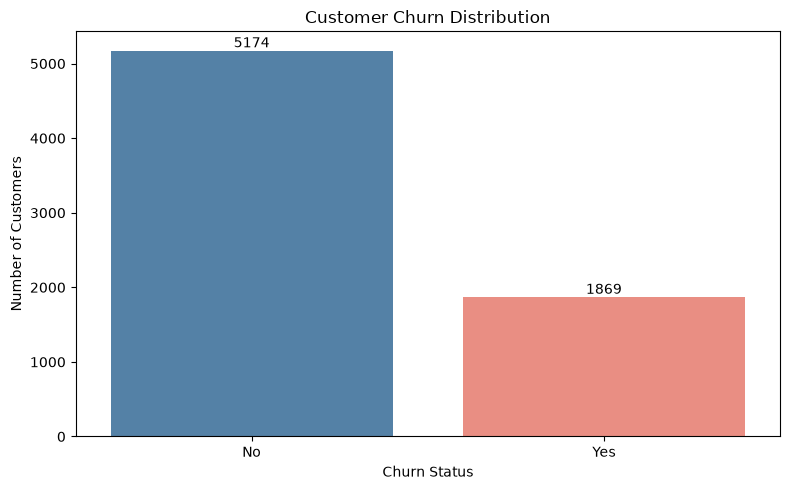

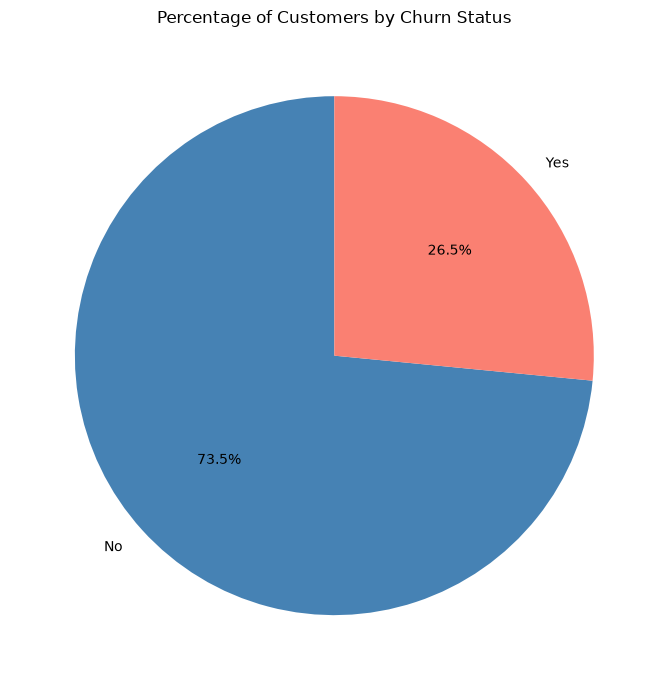

In [20]:
# Churn distribution bar chart

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Churn Label",
    order=["No", "Yes"],
    hue="Churn Label",
    palette={"No": "steelblue", "Yes": "salmon"},
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

# Churn percentage pie chart

plt.figure(figsize=(7, 7))

plt.pie(
    churn_counts,
    labels=churn_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["steelblue", "salmon"]
)

plt.title("Percentage of Customers by Churn Status")
plt.tight_layout()
plt.show()

In [21]:
# Calculate class imbalance ratio

class_counts = df["Churn Value"].value_counts()

majority_count = class_counts.max()
minority_count = class_counts.min()

imbalance_ratio = majority_count / minority_count

print(f"Majority Class: {majority_count}")
print(f"Minority Class: {minority_count}")
print(f"Class Imbalance Ratio: {imbalance_ratio:.2f}:1")

Majority Class: 5174
Minority Class: 1869
Class Imbalance Ratio: 2.77:1


# **Univariate Analysis**

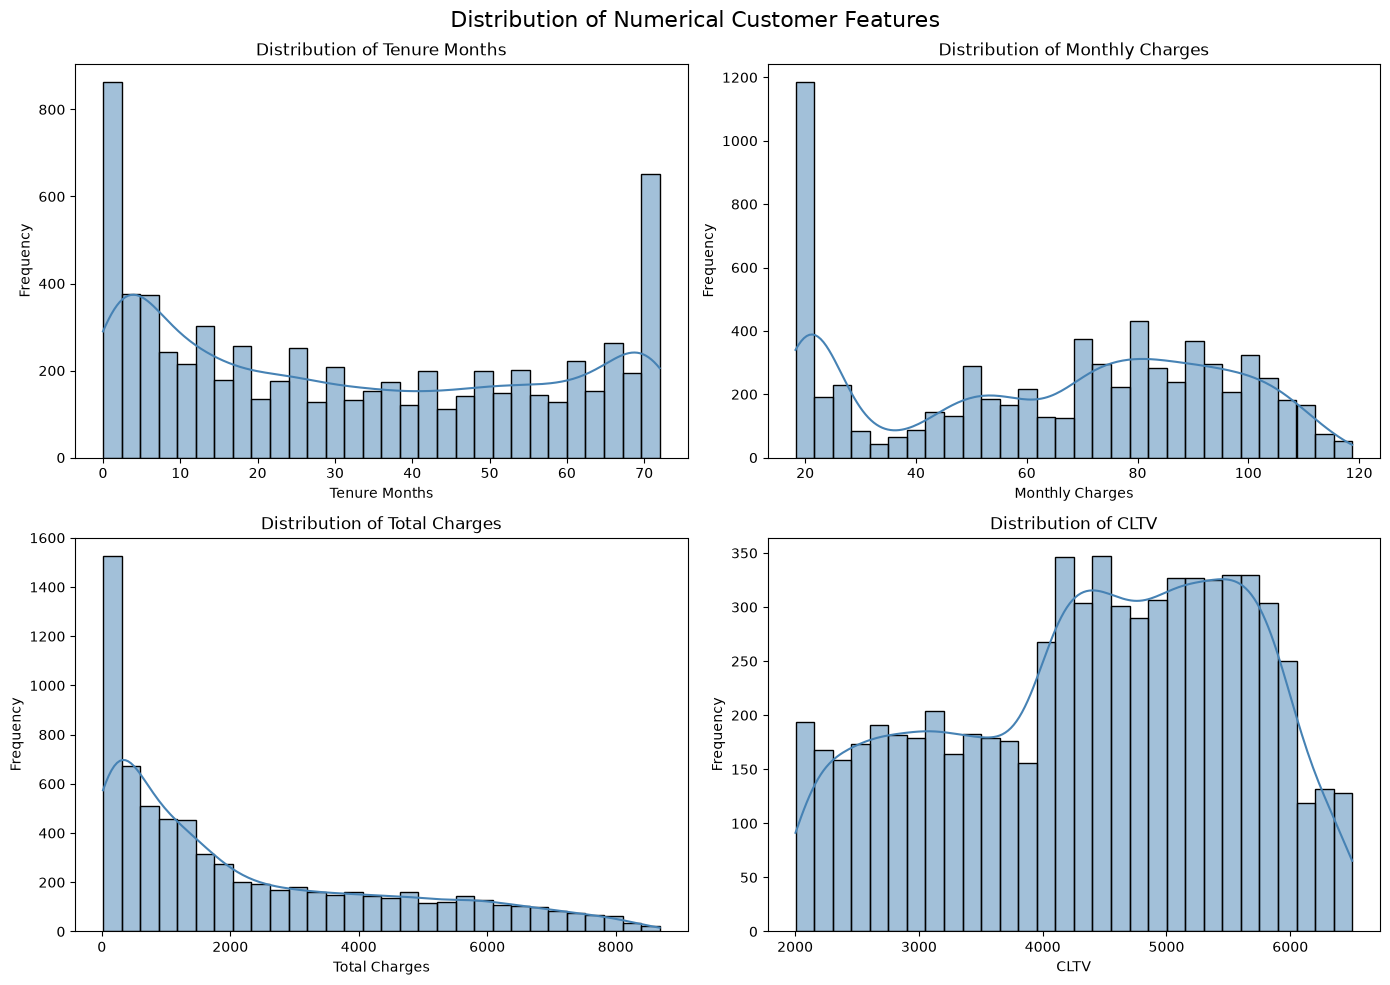

In [22]:
# Distribution of numerical features

eda_numeric_cols = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "CLTV"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes = axes.flatten()

for i, col in enumerate(eda_numeric_cols):

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30,
        color="steelblue",
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

plt.suptitle(
    "Distribution of Numerical Customer Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

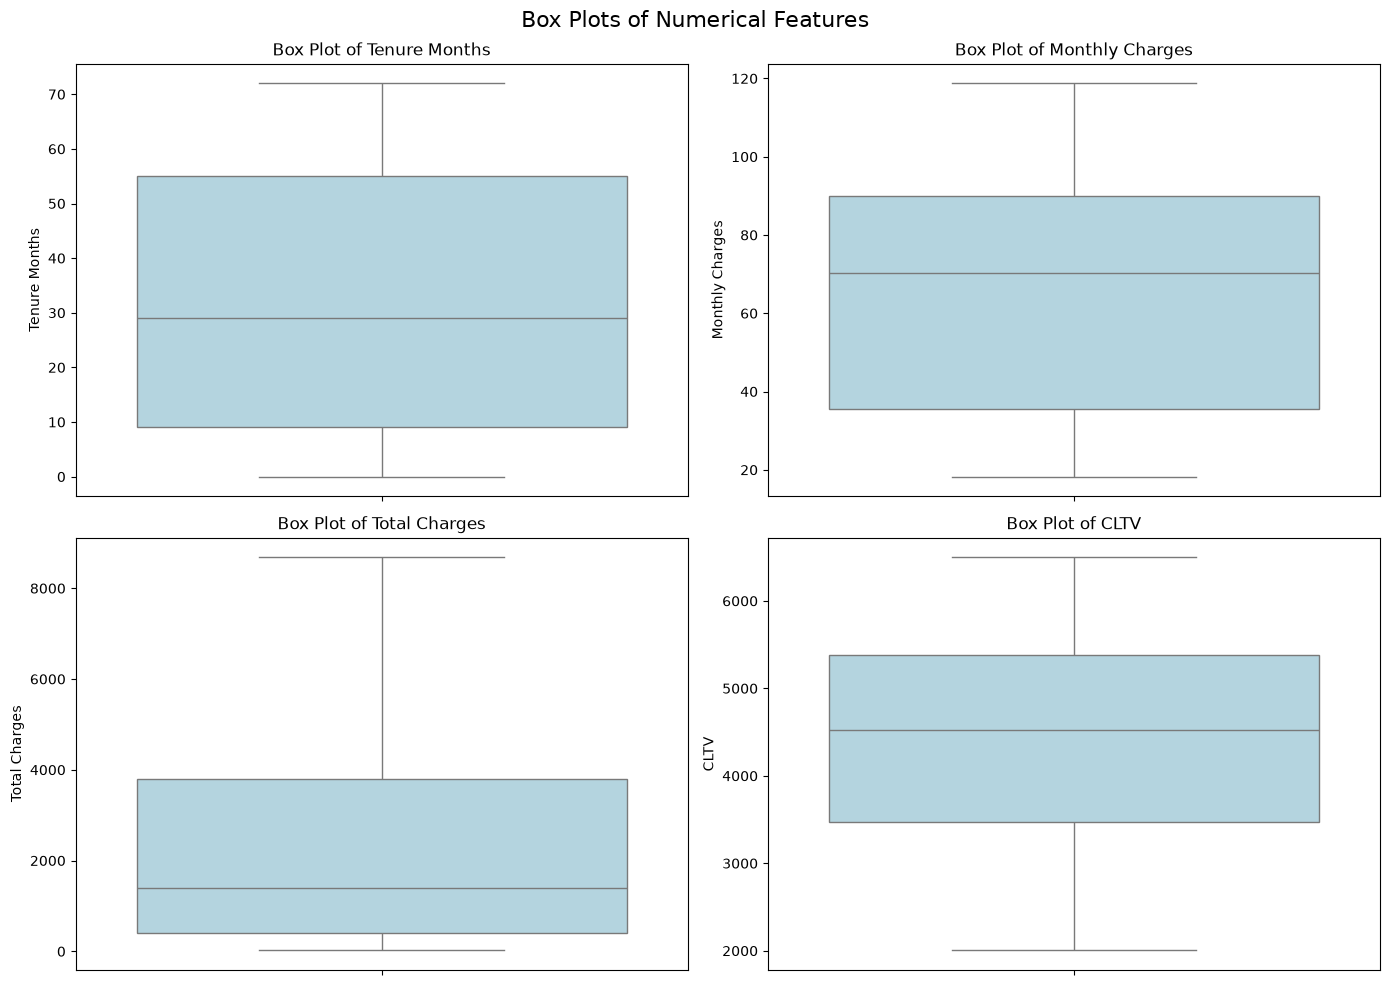

In [23]:
#  Box plots of numerical features

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes = axes.flatten()

for i, col in enumerate(eda_numeric_cols):

    sns.boxplot(
        data=df,
        y=col,
        color="lightblue",
        ax=axes[i]
    )

    axes[i].set_title(f"Box Plot of {col}")

plt.suptitle(
    "Box Plots of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [24]:
# Skewness analysis

skewness = df[eda_numeric_cols].skew()

skewness_df = pd.DataFrame({
    "Feature": skewness.index,
    "Skewness": skewness.values
})

skewness_df["Interpretation"] = skewness_df["Skewness"].apply(
    lambda x: (
        "Highly Skewed" if abs(x) > 1
        else "Moderately Skewed" if abs(x) > 0.5
        else "Approximately Symmetric"
    )
)

display(skewness_df)

,Feature,Skewness,Interpretation
0,Tenure Months,0.239540,Approximately Symmetric
1,Monthly Charges,-0.220524,Approximately Symmetric
2,Total Charges,0.961642,Moderately Skewed
3,CLTV,-0.311602,Approximately Symmetric


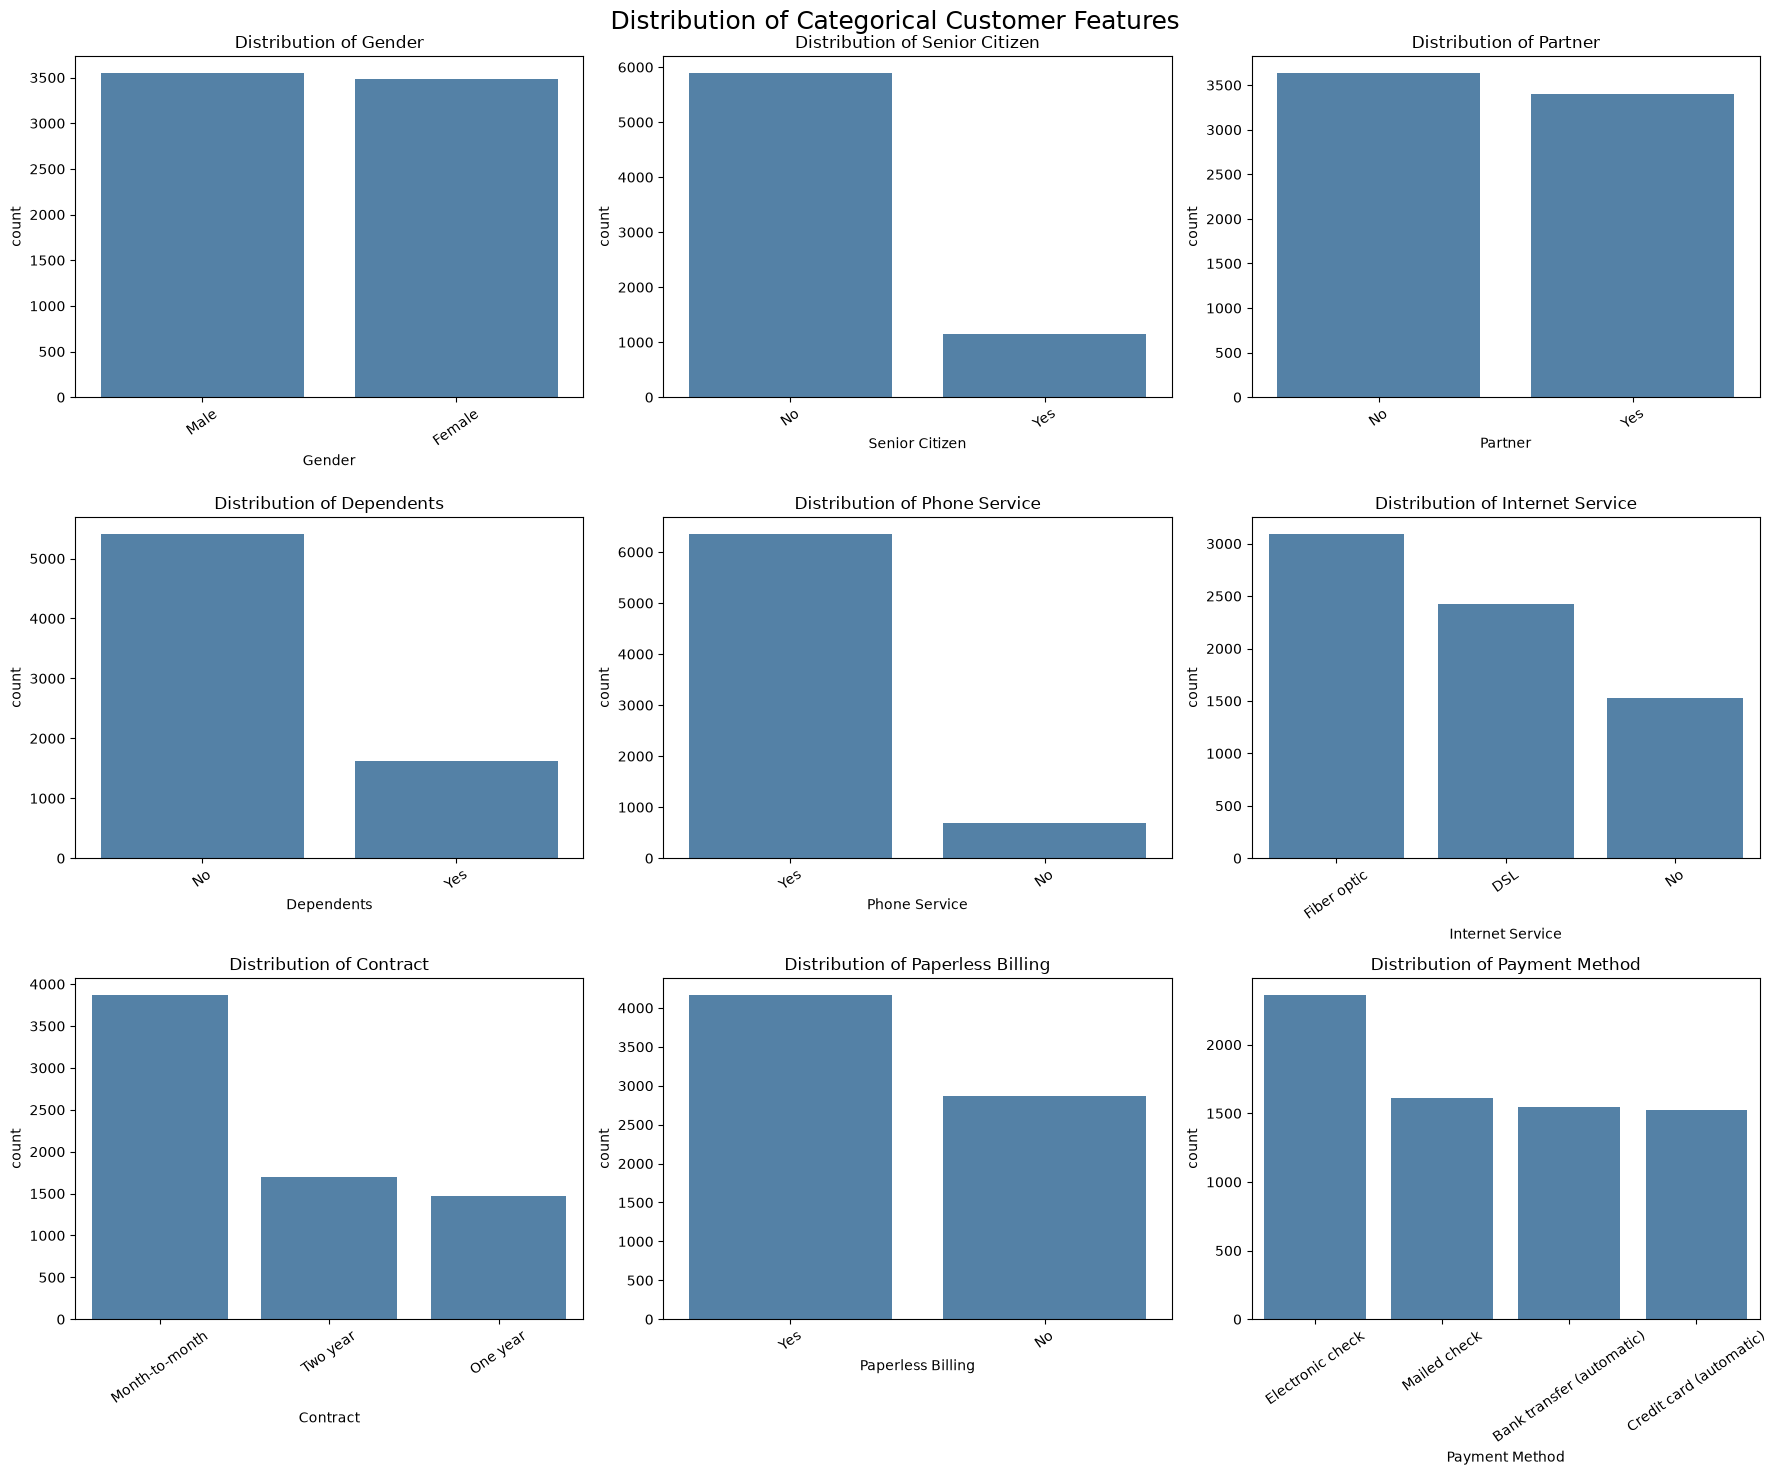

In [25]:
# Distribution of categorical features

categorical_features = [
    "Gender",
    "Senior Citizen",
    "Partner",
    "Dependents",
    "Phone Service",
    "Internet Service",
    "Contract",
    "Paperless Billing",
    "Payment Method"
]

fig, axes = plt.subplots(3, 3, figsize=(18, 15))

axes = axes.flatten()

for i, col in enumerate(categorical_features):

    sns.countplot(
        data=df,
        x=col,
        color="steelblue",
        order=df[col].value_counts().index,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].tick_params(axis="x", rotation=35)

plt.suptitle(
    "Distribution of Categorical Customer Features",
    fontsize=18
)

plt.tight_layout()
plt.show()



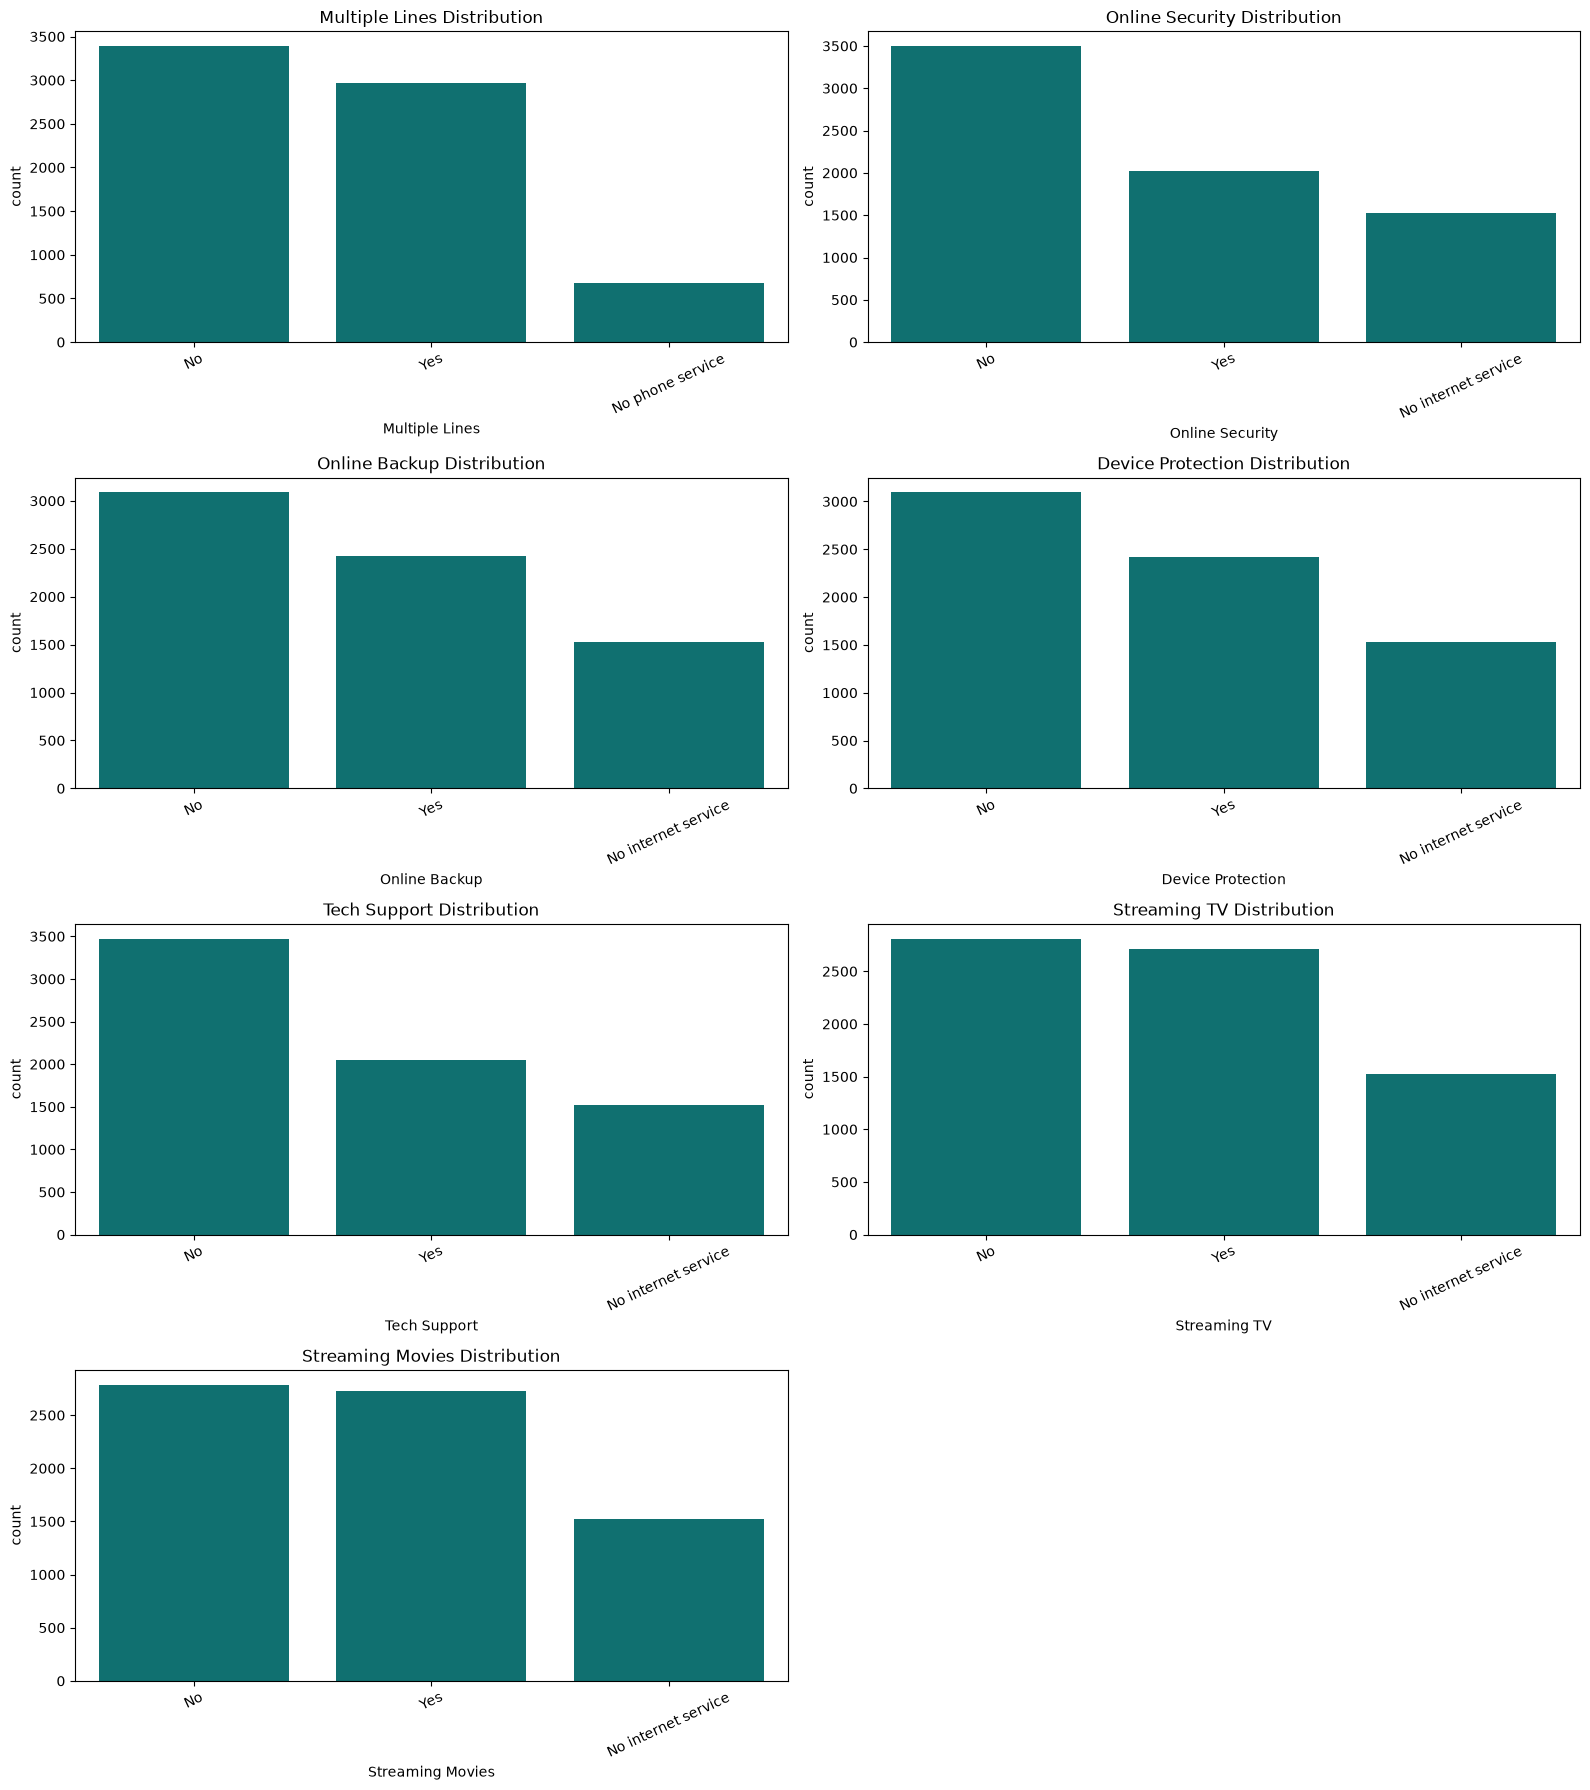

In [26]:
# Distribution of additional service subscriptions

service_features = [
    "Multiple Lines",
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Tech Support",
    "Streaming TV",
    "Streaming Movies"
]

fig, axes = plt.subplots(4, 2, figsize=(16, 18))

axes = axes.flatten()

for i, col in enumerate(service_features):

    sns.countplot(
        data=df,
        x=col,
        color="teal",
        order=df[col].value_counts().index,
        ax=axes[i]
    )

    axes[i].set_title(f"{col} Distribution")
    axes[i].tick_params(axis="x", rotation=25)

axes[-1].axis("off")

plt.tight_layout()
plt.show()

# **Bivariate Analysis: Features vs Customer Churn**

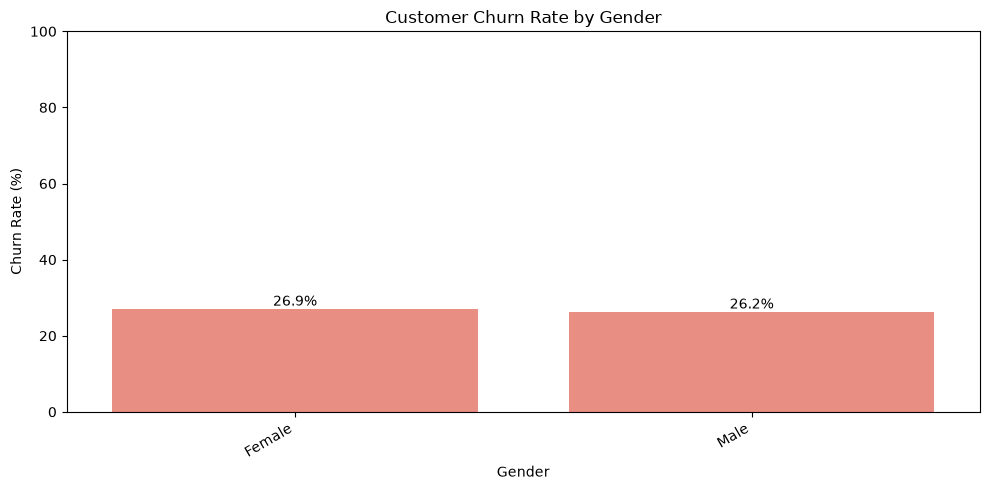

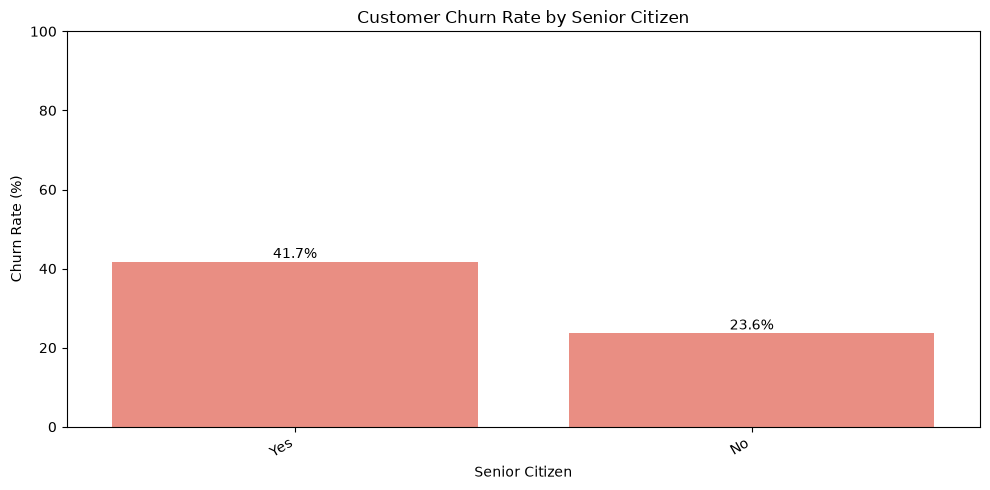

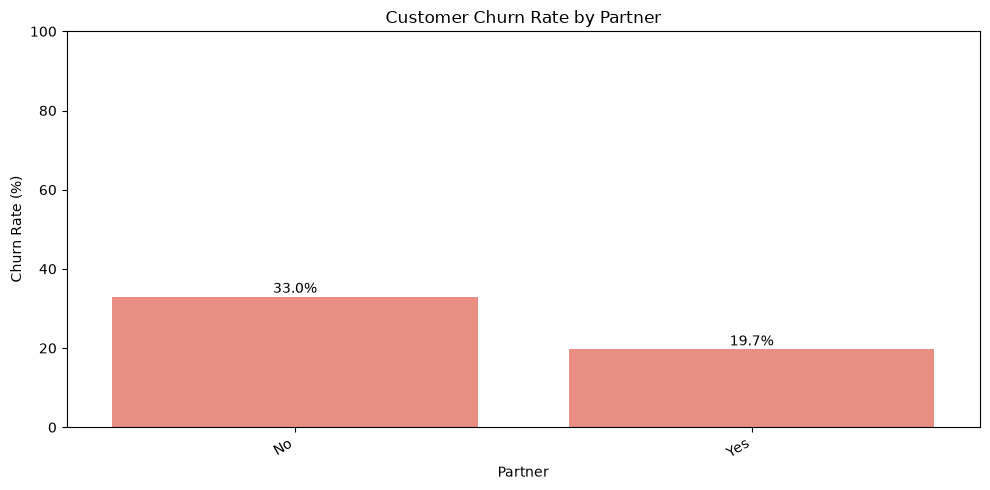

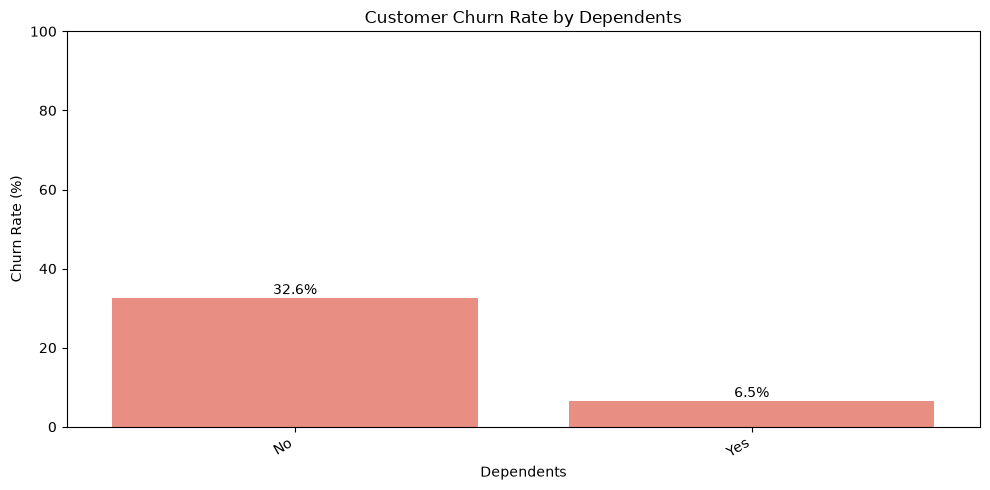

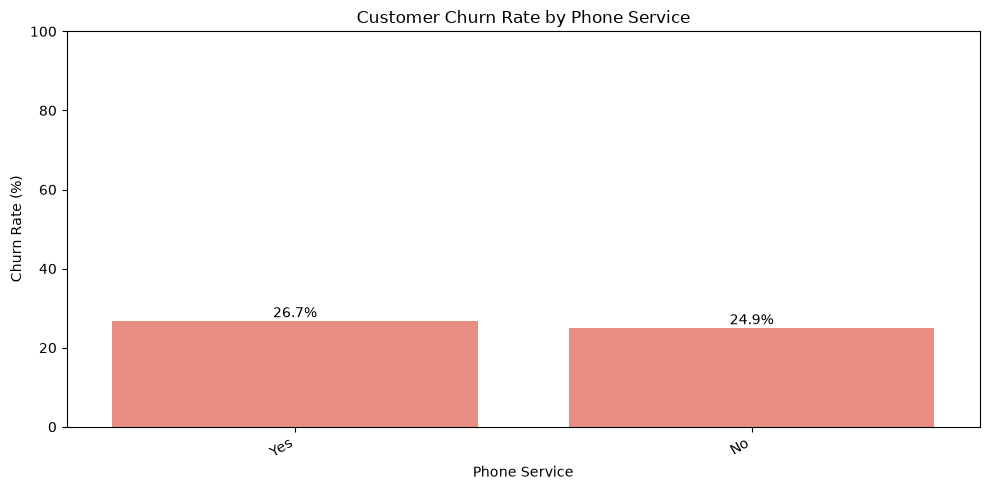

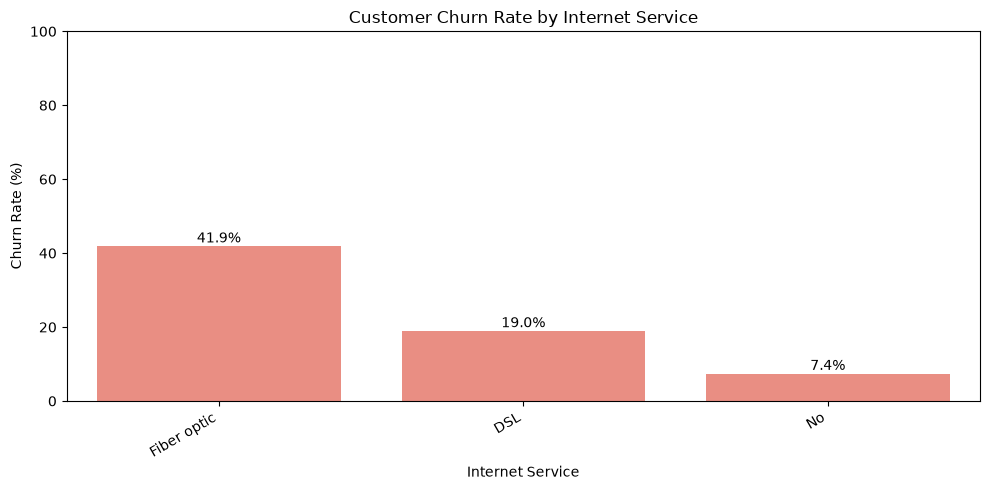

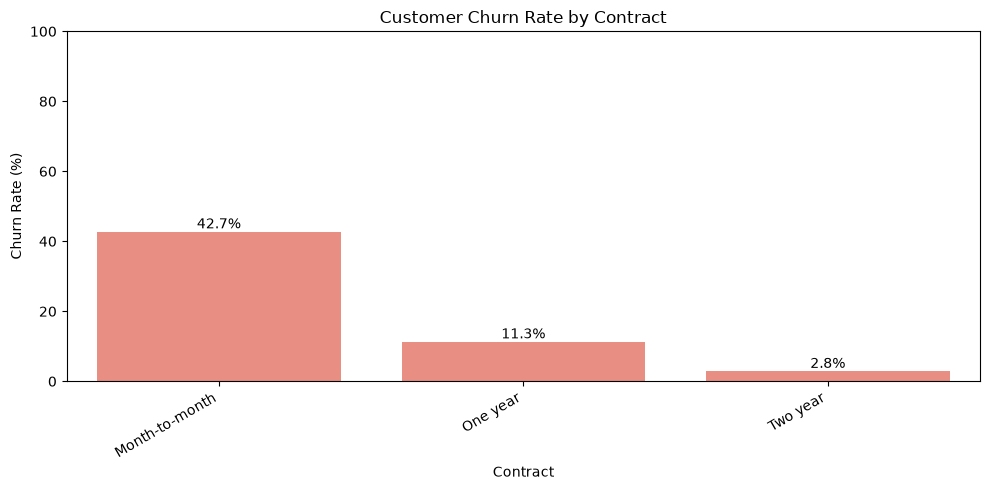

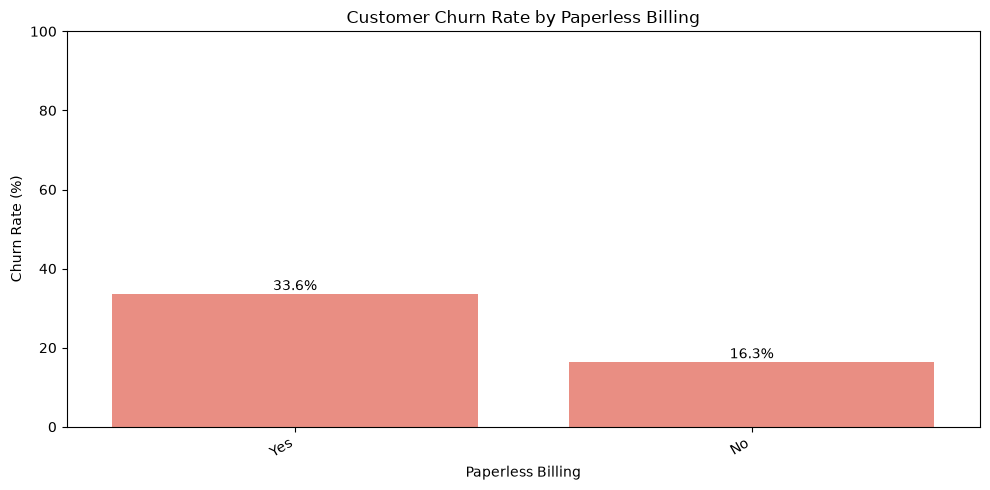

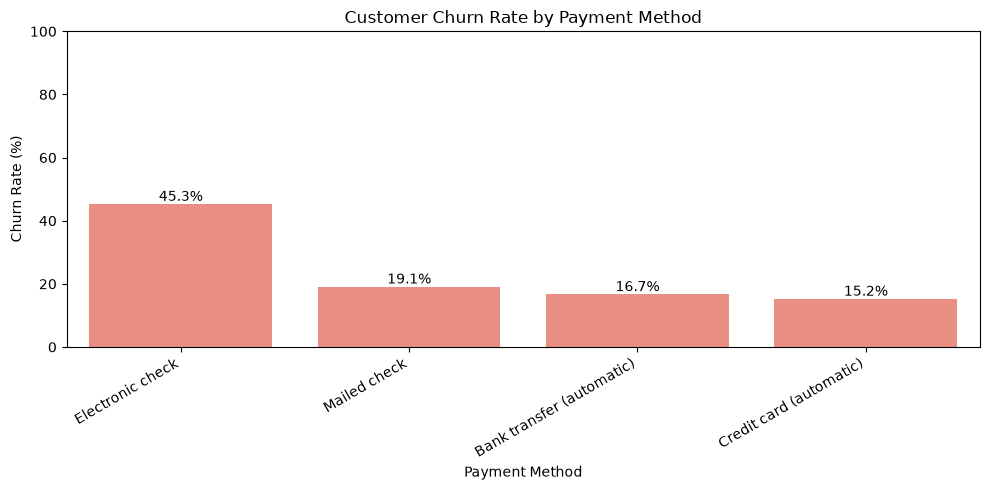

In [27]:
# Churn rate by categorical feature

def plot_churn_rate(data, column):

    churn_rate = (
        data.groupby(column, dropna=False)["Churn Value"]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 5))

    ax = sns.barplot(
        x=churn_rate.index.astype(str),
        y=churn_rate.values,
        color="salmon"
    )

    plt.title(f"Customer Churn Rate by {column}")
    plt.xlabel(column)
    plt.ylabel("Churn Rate (%)")
    plt.ylim(0, 100)
    plt.xticks(rotation=30, ha="right")

    for i, value in enumerate(churn_rate.values):
        ax.text(
            i,
            value + 1,
            f"{value:.1f}%",
            ha="center"
        )

    plt.tight_layout()
    plt.show()


for col in categorical_features:
    plot_churn_rate(df, col)

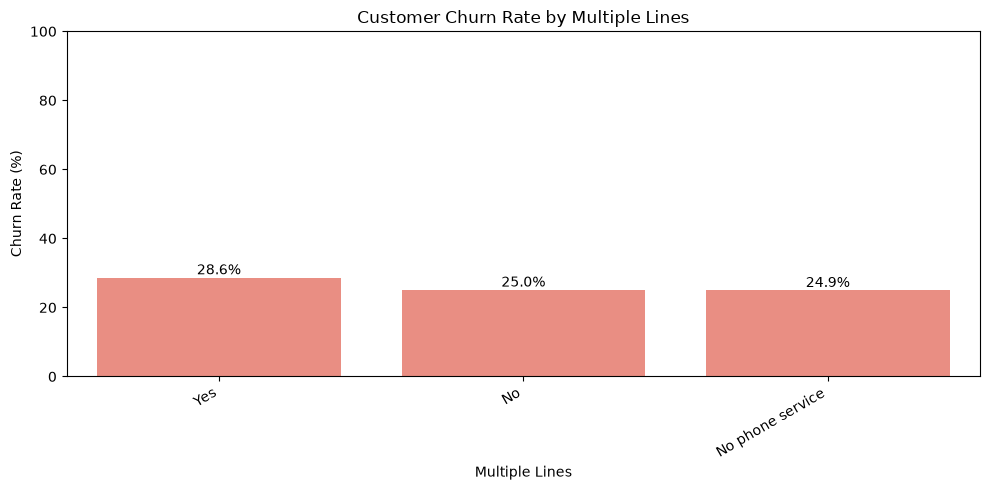

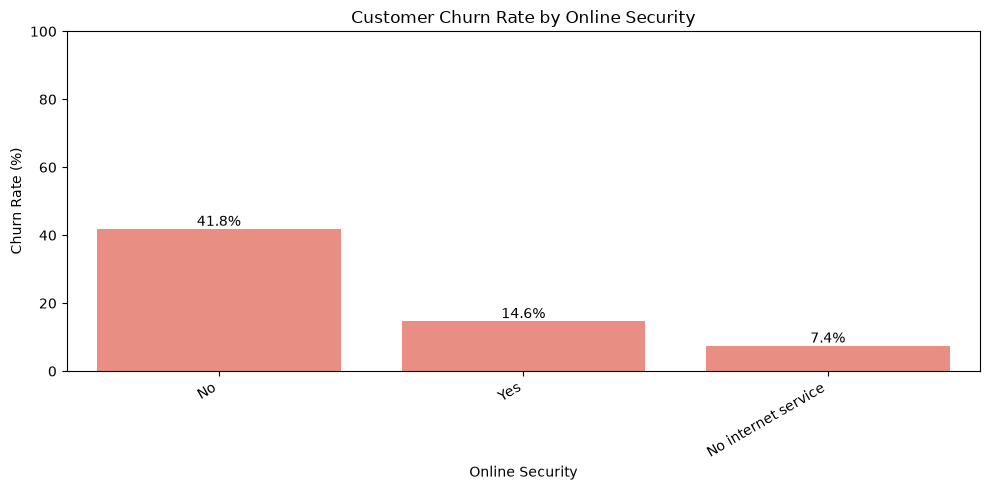

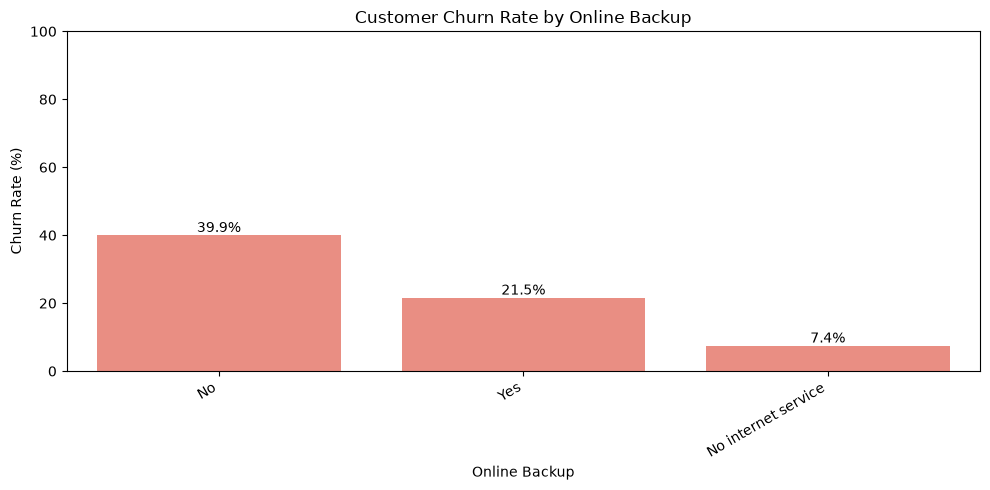

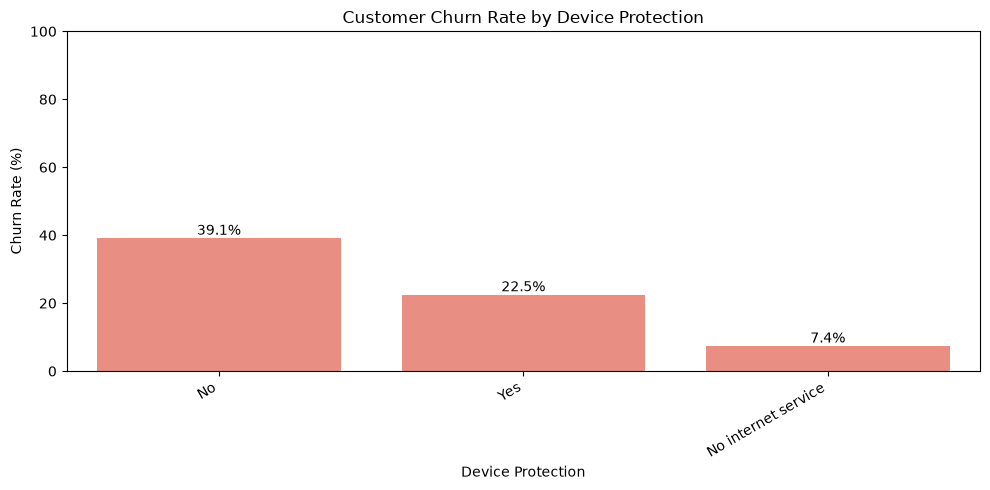

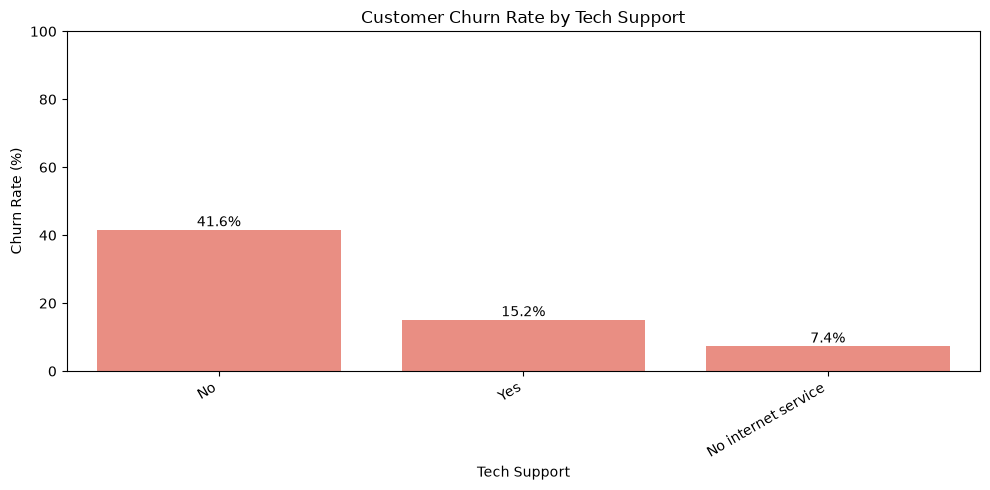

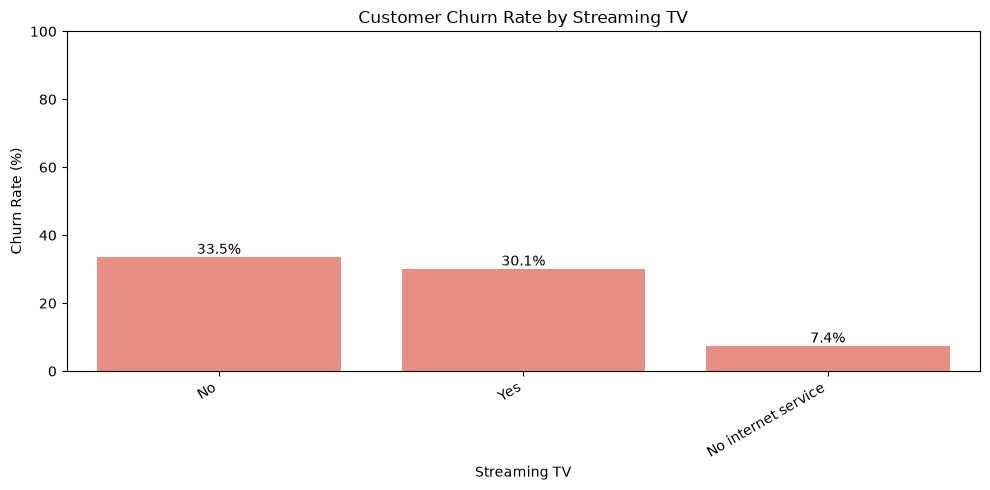

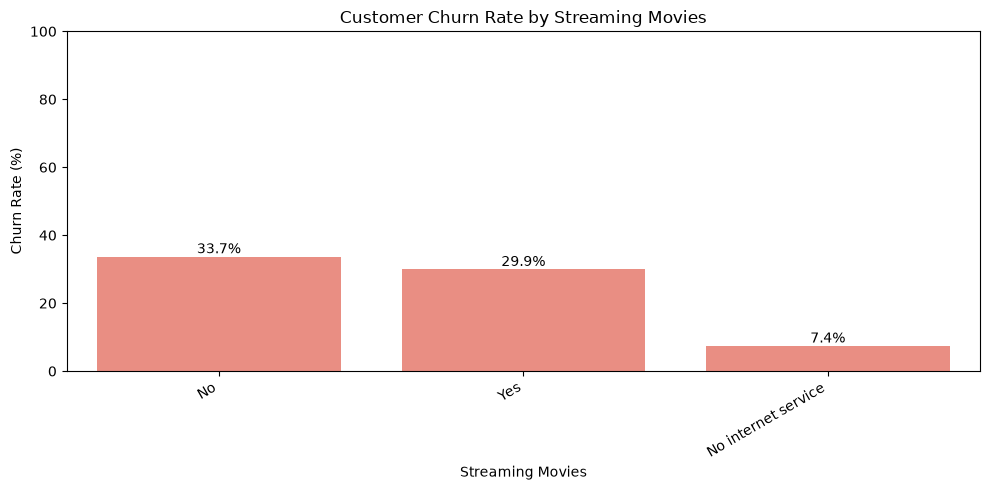

In [28]:
# Churn rate by service subscription

for col in service_features:
    plot_churn_rate(df, col)

Churn Label,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


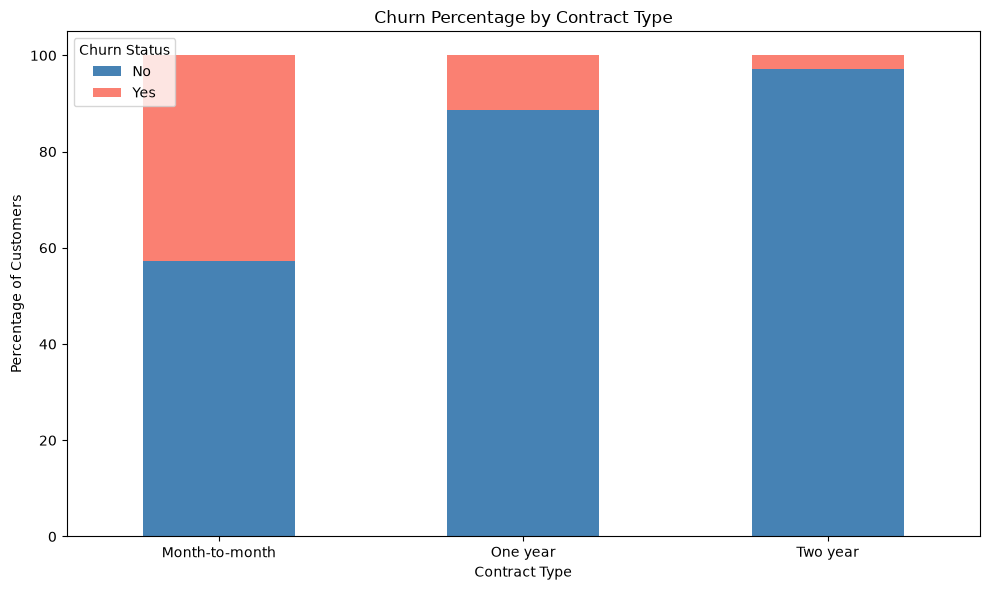

In [29]:
# Contract type vs churn

contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn Label"],
    normalize="index"
) * 100

display(contract_churn.round(2))

contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["steelblue", "salmon"]
)

plt.title("Churn Percentage by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Churn Status")
plt.tight_layout()
plt.show()

Churn Label,No,Yes
Internet Service,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


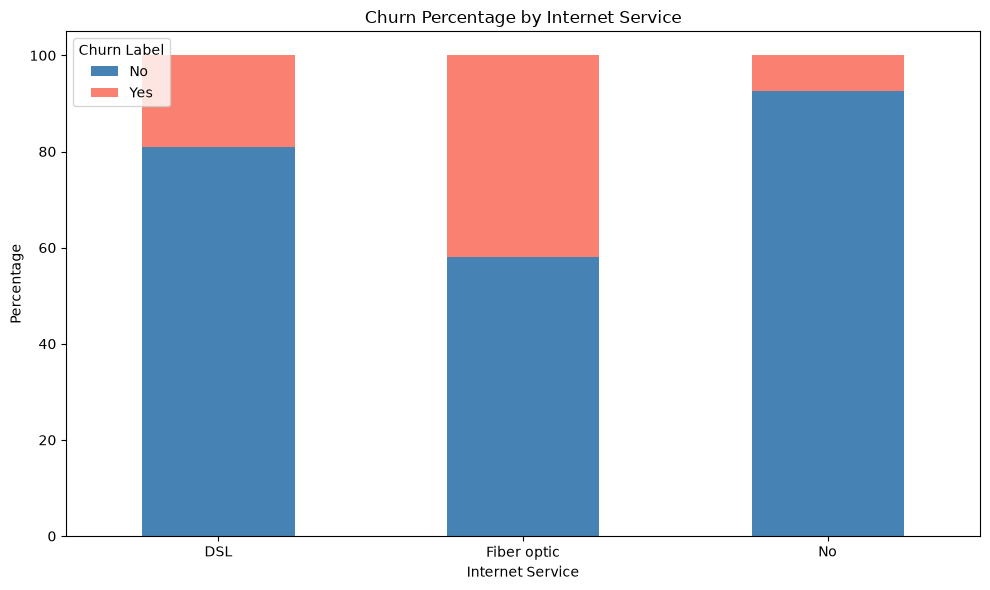

In [30]:
# Internet service vs churn

internet_churn = pd.crosstab(
    df["Internet Service"],
    df["Churn Label"],
    normalize="index"
) * 100

display(internet_churn.round(2))

internet_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["steelblue", "salmon"]
)

plt.title("Churn Percentage by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Churn Label,No,Yes
Payment Method,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


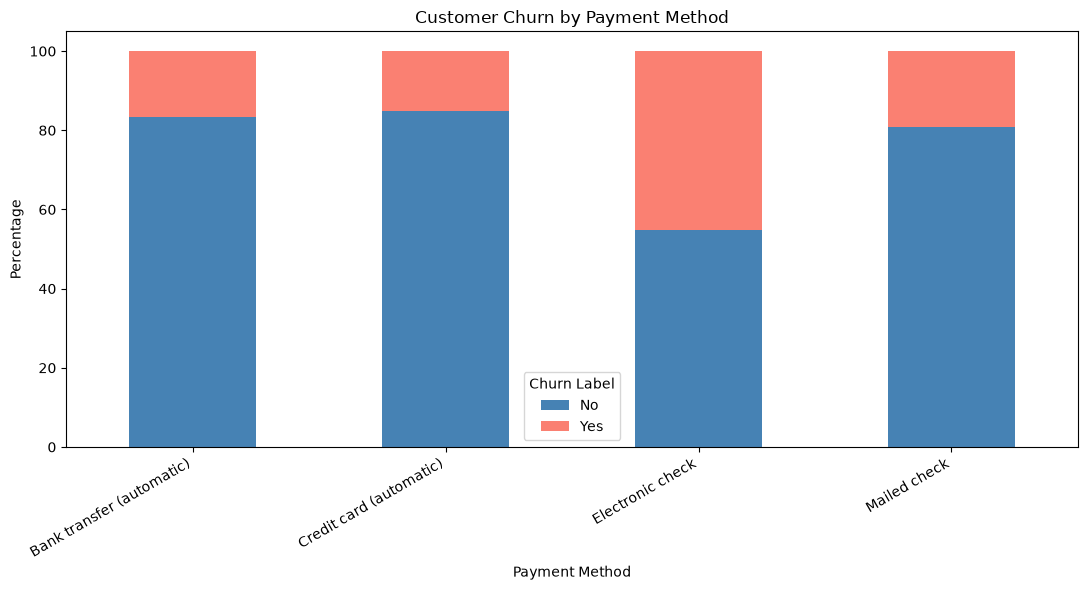

In [31]:
# Payment method vs churn

payment_churn = pd.crosstab(
    df["Payment Method"],
    df["Churn Label"],
    normalize="index"
) * 100

display(payment_churn.round(2))

payment_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6),
    color=["steelblue", "salmon"]
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Percentage")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


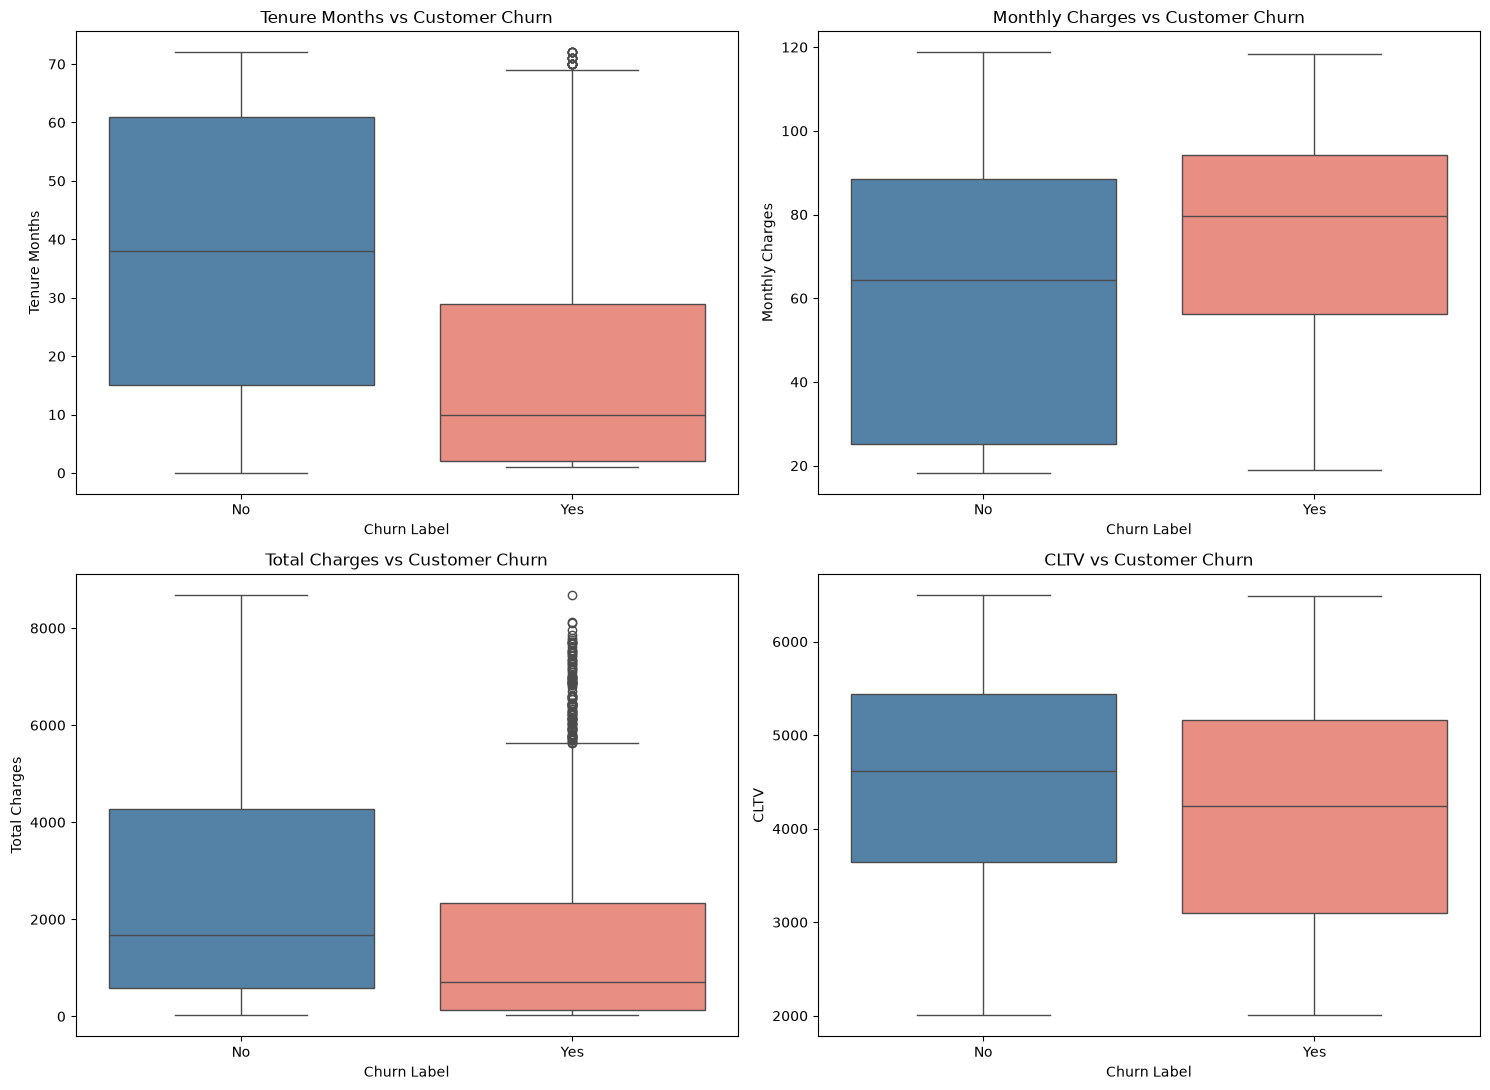

In [32]:
# Numerical feature distributions by churn

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

axes = axes.flatten()

for i, col in enumerate(eda_numeric_cols):

    sns.boxplot(
        data=df,
        x="Churn Label",
        y=col,
        order=["No", "Yes"],
        hue="Churn Label",
        palette={"No": "steelblue", "Yes": "salmon"},
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(f"{col} vs Customer Churn")

plt.tight_layout()
plt.show()

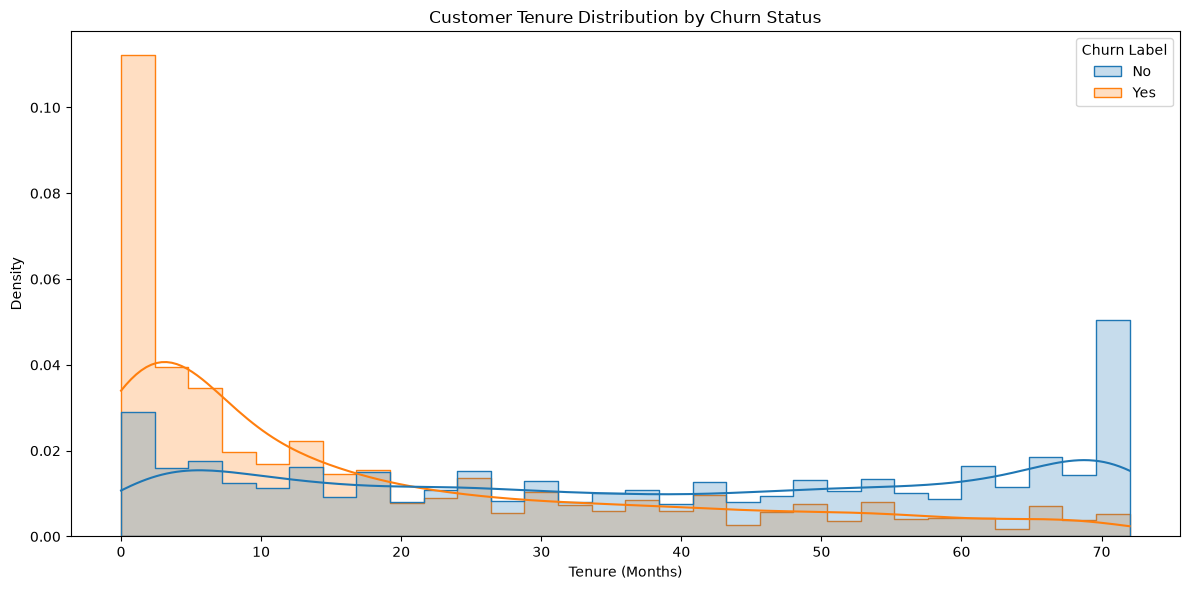

In [33]:
# Tenure distribution by churn status

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="Tenure Months",
    hue="Churn Label",
    hue_order=["No", "Yes"],
    kde=True,
    bins=30,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Customer Tenure Distribution by Churn Status")
plt.xlabel("Tenure (Months)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

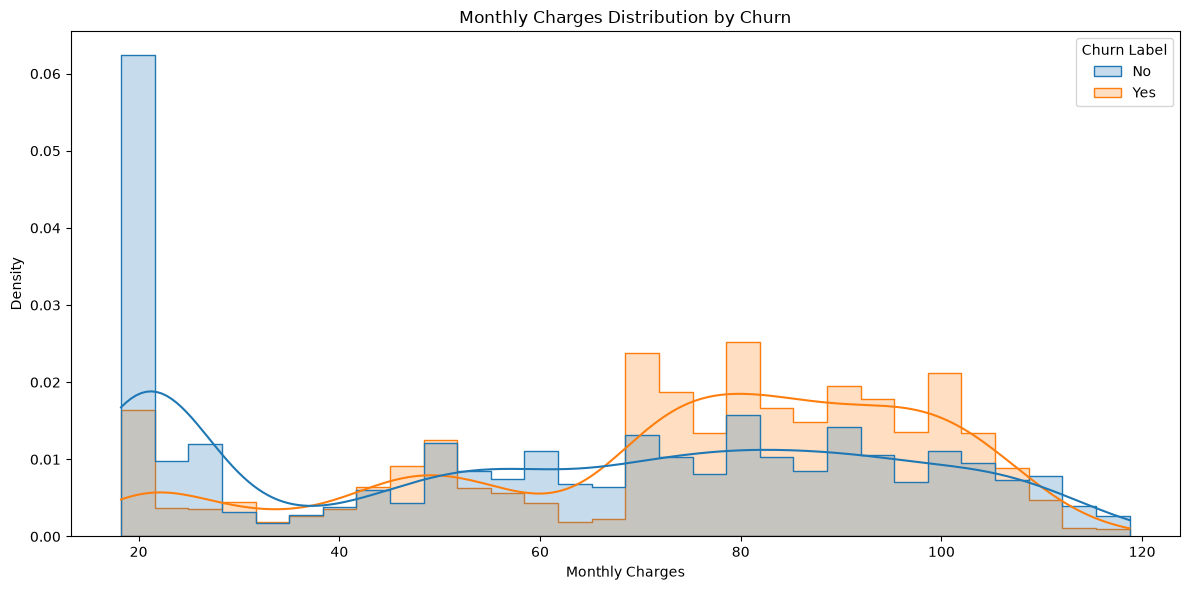

In [34]:
# Monthly charges distribution by churn

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="Monthly Charges",
    hue="Churn Label",
    hue_order=["No", "Yes"],
    kde=True,
    bins=30,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Monthly Charges Distribution by Churn")
plt.xlabel("Monthly Charges")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

In [35]:
# Average numerical features by churn status

average_by_churn = df.groupby(
    "Churn Label"
)[eda_numeric_cols].mean()

display(average_by_churn.round(2))

,Tenure Months,Monthly Charges,Total Charges,CLTV
Churn Label,,,,
No,37.57,61.27,2555.34,4490.92
Yes,17.98,74.44,1531.80,4149.41


,count,mean,Churn Rate (%)
Tenure Group,,,
0-12 Months,2186,0.474382,47.438243
13-24 Months,1024,0.287109,28.710938
25-36 Months,832,0.216346,21.634615
37-48 Months,762,0.190289,19.028871
49-60 Months,832,0.144231,14.423077
61-72 Months,1407,0.066098,6.609808


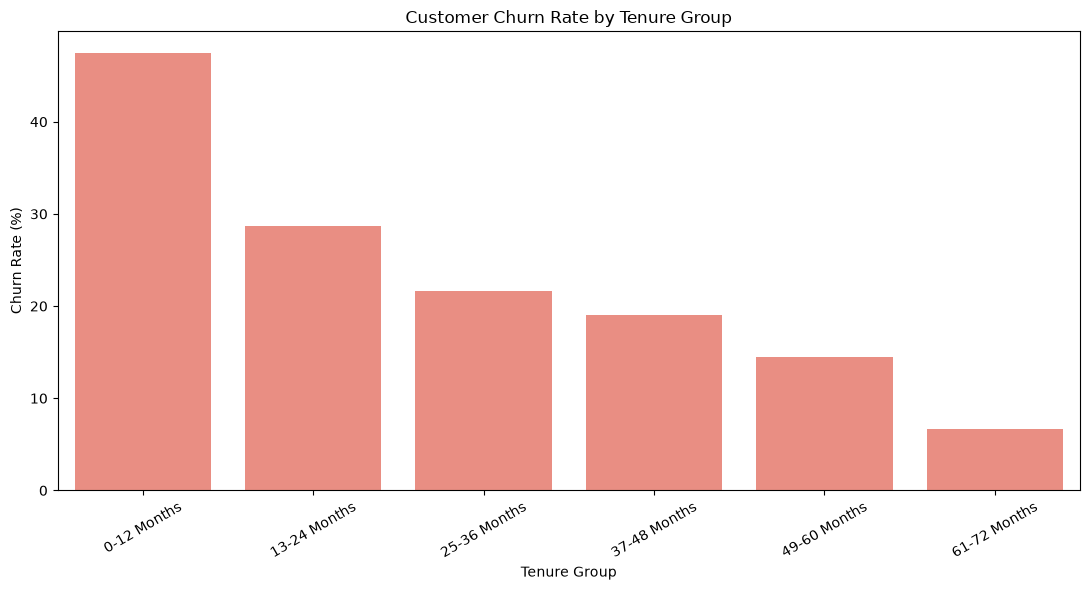

In [36]:
# Churn rate by tenure group

df["Tenure Group"] = pd.cut(
    df["Tenure Months"],
    bins=[-1, 12, 24, 36, 48, 60, 72],
    labels=[
        "0-12 Months",
        "13-24 Months",
        "25-36 Months",
        "37-48 Months",
        "49-60 Months",
        "61-72 Months"
    ]
)

tenure_churn = (
    df.groupby(
        "Tenure Group",
        observed=True
    )["Churn Value"]
    .agg(["count", "mean"])
)

tenure_churn["Churn Rate (%)"] = tenure_churn["mean"] * 100

display(tenure_churn)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=tenure_churn.index.astype(str),
    y=tenure_churn["Churn Rate (%)"],
    color="salmon"
)

plt.title("Customer Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,count,mean,Churn Rate (%)
Monthly Charge Group,,,
"(18.249, 25.05]",1420,0.091549,9.154930
"(25.05, 58.83]",1397,0.249821,24.982105
"(58.83, 79.1]",1411,0.297661,29.766123
"(79.1, 94.25]",1407,0.361052,36.105188
"(94.25, 118.75]",1408,0.328125,32.812500


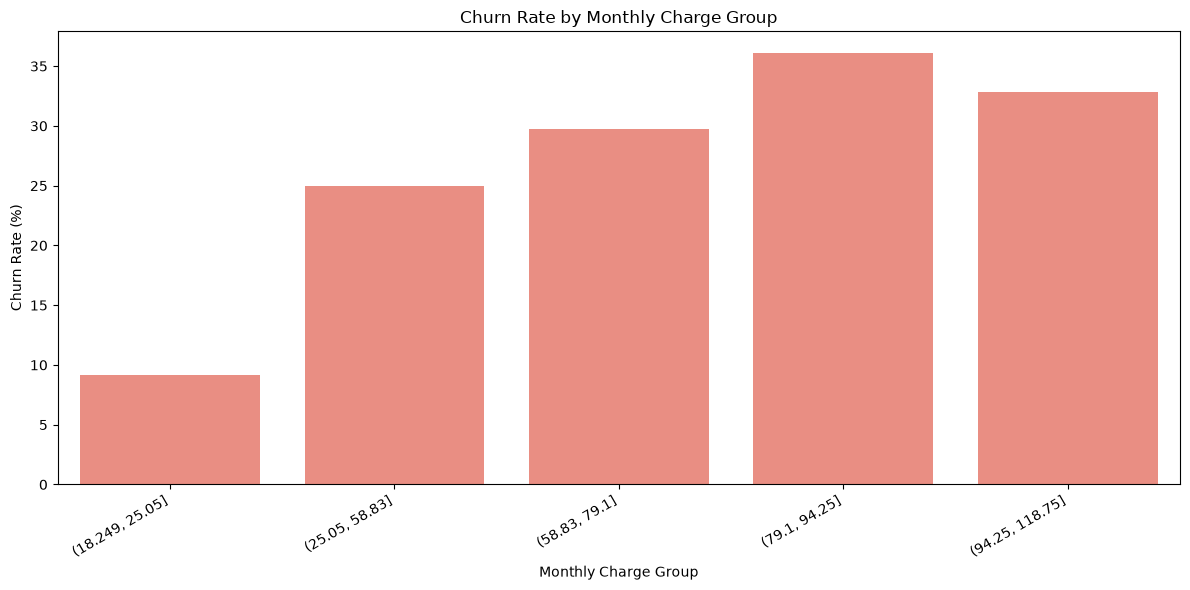

In [37]:
# Churn rate by monthly charge group

df["Monthly Charge Group"] = pd.qcut(
    df["Monthly Charges"],
    q=5,
    duplicates="drop"
)

charge_churn = (
    df.groupby(
        "Monthly Charge Group",
        observed=True
    )["Churn Value"]
    .agg(["count", "mean"])
)

charge_churn["Churn Rate (%)"] = charge_churn["mean"] * 100

display(charge_churn)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=charge_churn.index.astype(str),
    y=charge_churn["Churn Rate (%)"],
    color="salmon"
)

plt.title("Churn Rate by Monthly Charge Group")
plt.xlabel("Monthly Charge Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# **Multivariate Analysis**

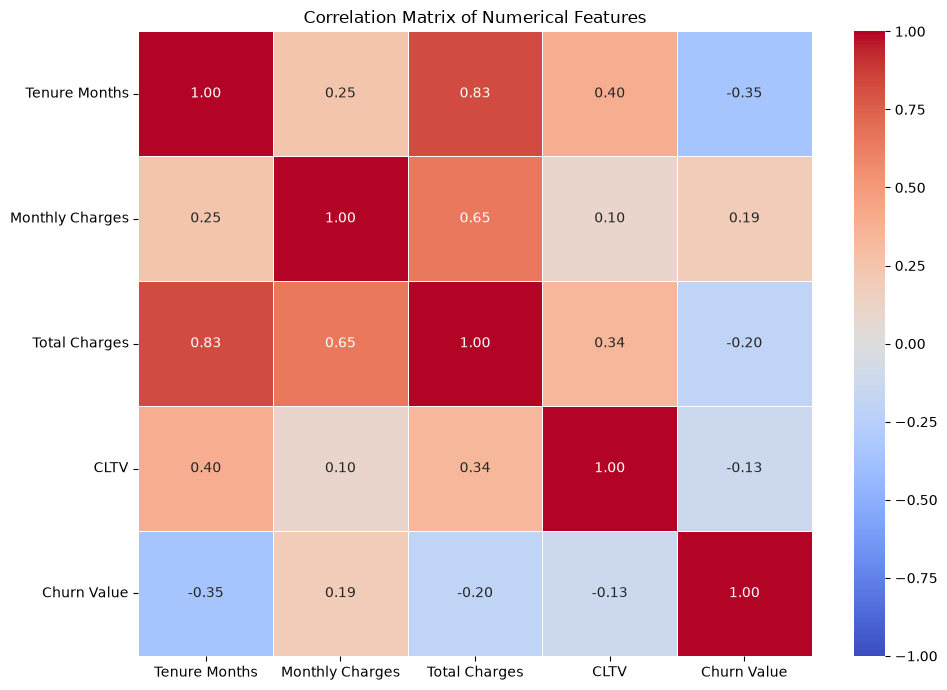

In [38]:
# Correlation heatmap

correlation_features = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "CLTV",
    "Churn Value"
]

correlation_matrix = df[
    correlation_features
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

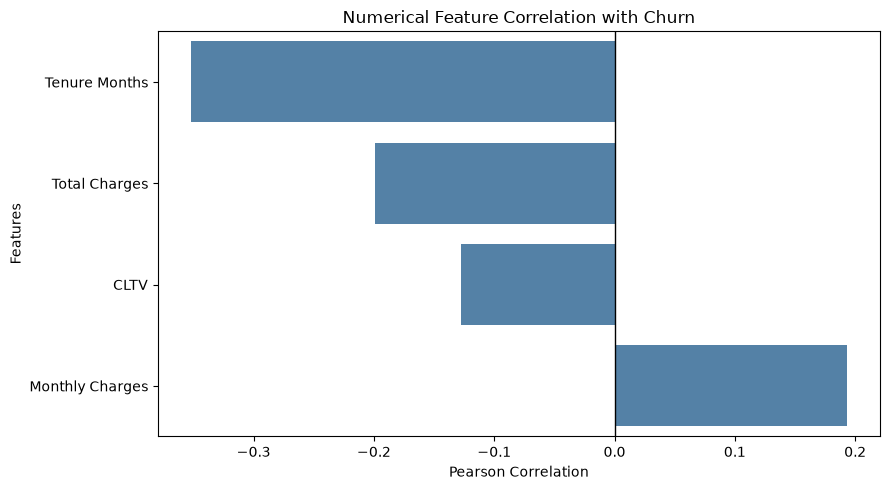

Tenure Months     -0.352229
Total Charges     -0.199484
CLTV              -0.127463
Monthly Charges    0.193356
Name: Churn Value, dtype: float64

In [39]:
# Correlation with churn target

target_correlation = (
    correlation_matrix["Churn Value"]
    .drop("Churn Value")
    .sort_values()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=target_correlation.values,
    y=target_correlation.index,
    color="steelblue"
)

plt.title("Numerical Feature Correlation with Churn")
plt.xlabel("Pearson Correlation")
plt.ylabel("Features")
plt.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

display(target_correlation)


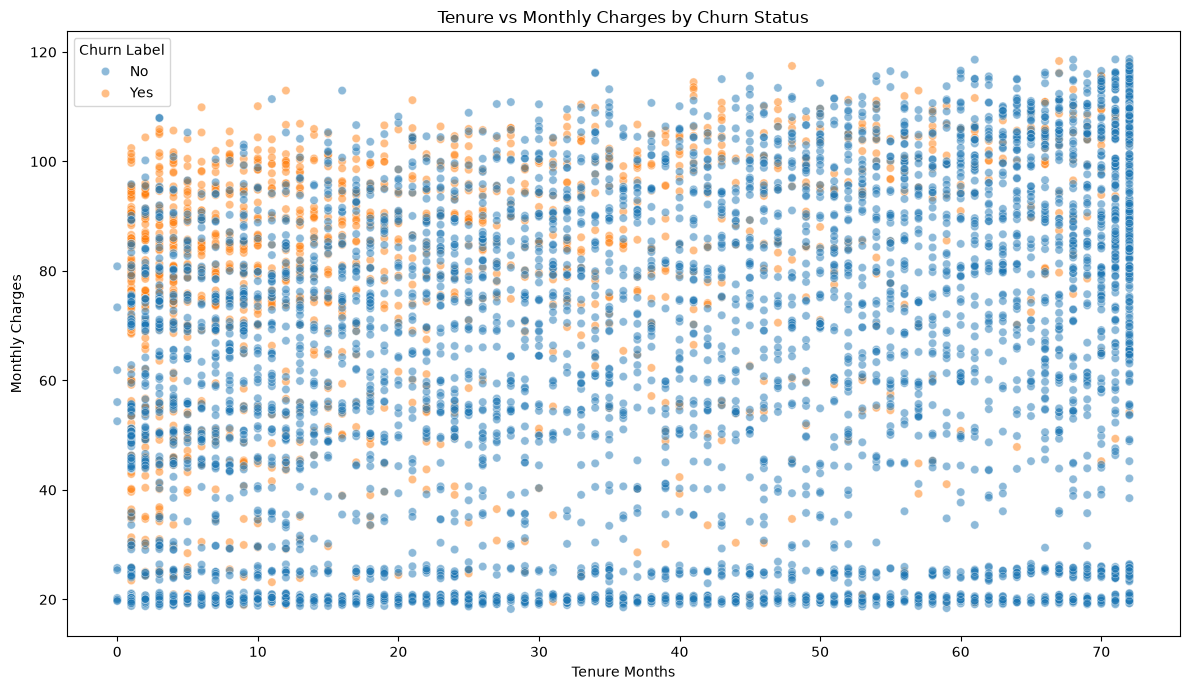

In [40]:
# Tenure vs monthly charges by churn

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="Tenure Months",
    y="Monthly Charges",
    hue="Churn Label",
    hue_order=["No", "Yes"],
    alpha=0.5
)

plt.title("Tenure vs Monthly Charges by Churn Status")
plt.xlabel("Tenure Months")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

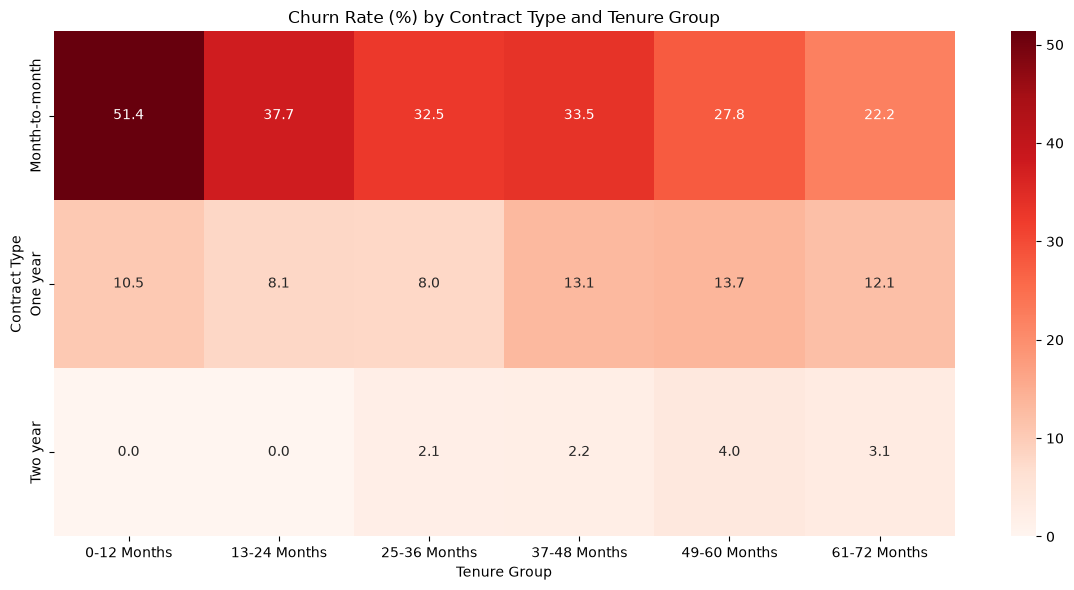

In [41]:
# Contract type and tenure group interaction

contract_tenure_churn = pd.pivot_table(
    df,
    values="Churn Value",
    index="Contract",
    columns="Tenure Group",
    aggfunc="mean",
    observed=True
) * 100

plt.figure(figsize=(12, 6))

sns.heatmap(
    contract_tenure_churn,
    annot=True,
    fmt=".1f",
    cmap="Reds"
)

plt.title("Churn Rate (%) by Contract Type and Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Contract Type")
plt.tight_layout()
plt.show()

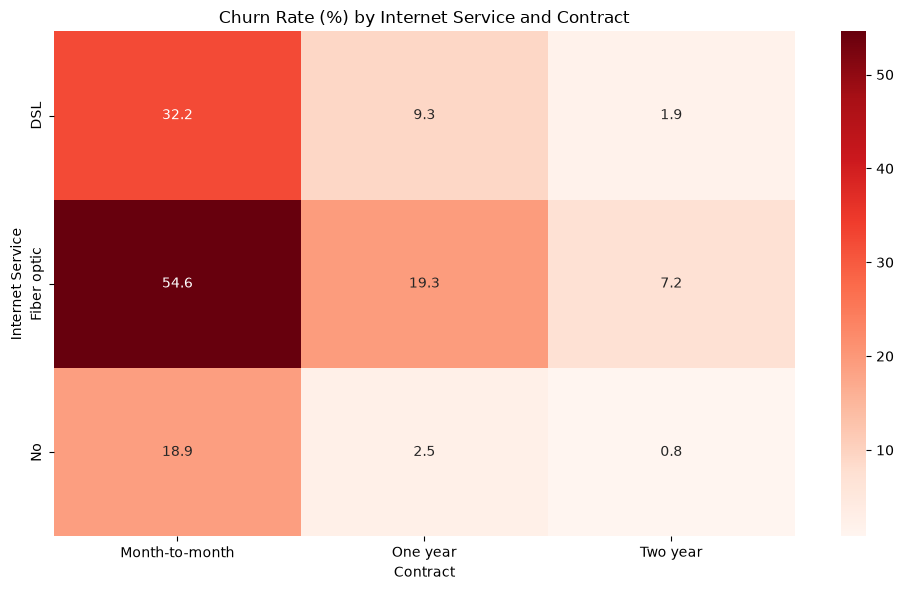

In [42]:
# Internet service and contract interaction

internet_contract_churn = pd.pivot_table(
    df,
    values="Churn Value",
    index="Internet Service",
    columns="Contract",
    aggfunc="mean"
) * 100

plt.figure(figsize=(10, 6))

sns.heatmap(
    internet_contract_churn,
    annot=True,
    fmt=".1f",
    cmap="Reds"
)

plt.title("Churn Rate (%) by Internet Service and Contract")
plt.tight_layout()
plt.show()

# **Outlier Analysis**

In [43]:
# Identify outliers using the IQR method

outlier_results = []

for col in eda_numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": (
            len(outliers) / len(df)
        ) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df.round(2))

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Tenure Months,-60.00,124.00,0,0.0
1,Monthly Charges,-46.02,171.38,0,0.0
2,Total Charges,-4688.48,8884.67,0,0.0
3,CLTV,601.75,8247.75,0,0.0


# **Customer Segmentation Analysis**

,count,mean,Churn Rate (%)
Senior Citizen,,,
No,5901,0.24,23.61
Yes,1142,0.42,41.68


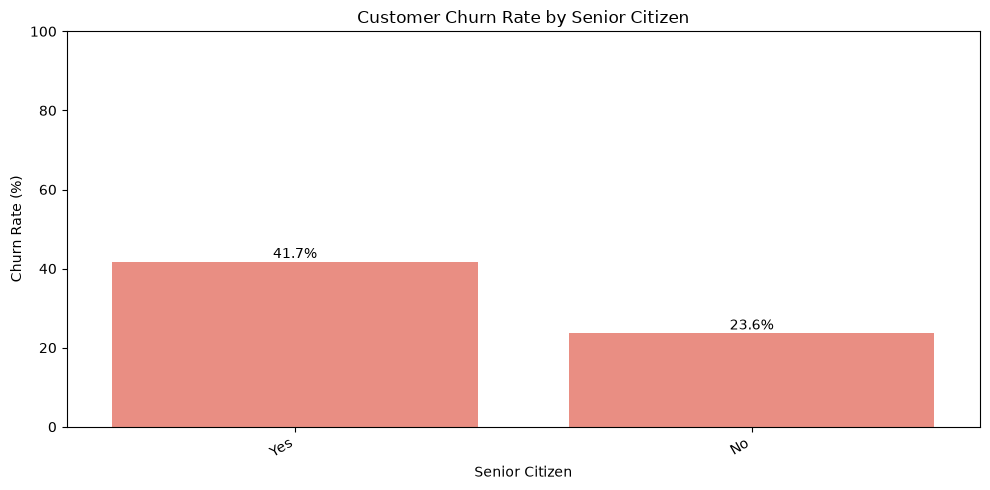

In [45]:
# Churn rate by senior citizen status

senior_churn = df.groupby(
    "Senior Citizen"
)["Churn Value"].agg(["count", "mean"])

senior_churn["Churn Rate (%)"] = senior_churn["mean"] * 100

display(senior_churn.round(2))

plot_churn_rate(df, "Senior Citizen")

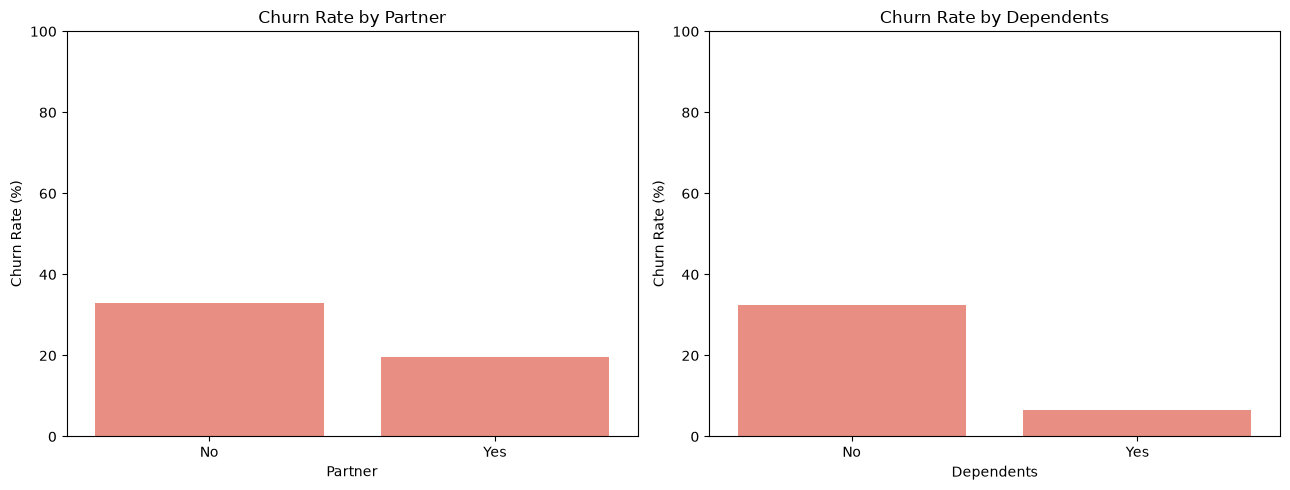

In [46]:
# Churn rate by partner and dependents

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for i, col in enumerate(["Partner", "Dependents"]):

    churn_rates = (
        df.groupby(col)["Churn Value"]
        .mean() * 100
    )

    sns.barplot(
        x=churn_rates.index,
        y=churn_rates.values,
        color="salmon",
        ax=axes[i]
    )

    axes[i].set_title(f"Churn Rate by {col}")
    axes[i].set_ylabel("Churn Rate (%)")
    axes[i].set_ylim(0, 100)

plt.tight_layout()
plt.show()


In [47]:
# Customer segment risk analysis

segment_analysis = (
    df.groupby(
        ["Contract", "Internet Service"],
        dropna=False
    )
    .agg(
        Total_Customers=("CustomerID", "count"),
        Churned_Customers=("Churn Value", "sum"),
        Churn_Rate=("Churn Value", "mean")
    )
    .reset_index()
)

segment_analysis["Churn_Rate"] *= 100

segment_analysis = segment_analysis.sort_values(
    by="Churn_Rate",
    ascending=False
)

display(segment_analysis.round(2))

,Contract,Internet Service,Total_Customers,Churned_Customers,Churn_Rate
1,Month-to-month,Fiber optic,2128,1162,54.61
0,Month-to-month,DSL,1223,394,32.22
4,One year,Fiber optic,539,104,19.29
2,Month-to-month,No,524,99,18.89
3,One year,DSL,570,53,9.30
7,Two year,Fiber optic,429,31,7.23
5,One year,No,364,9,2.47
6,Two year,DSL,628,12,1.91
8,Two year,No,638,5,0.78


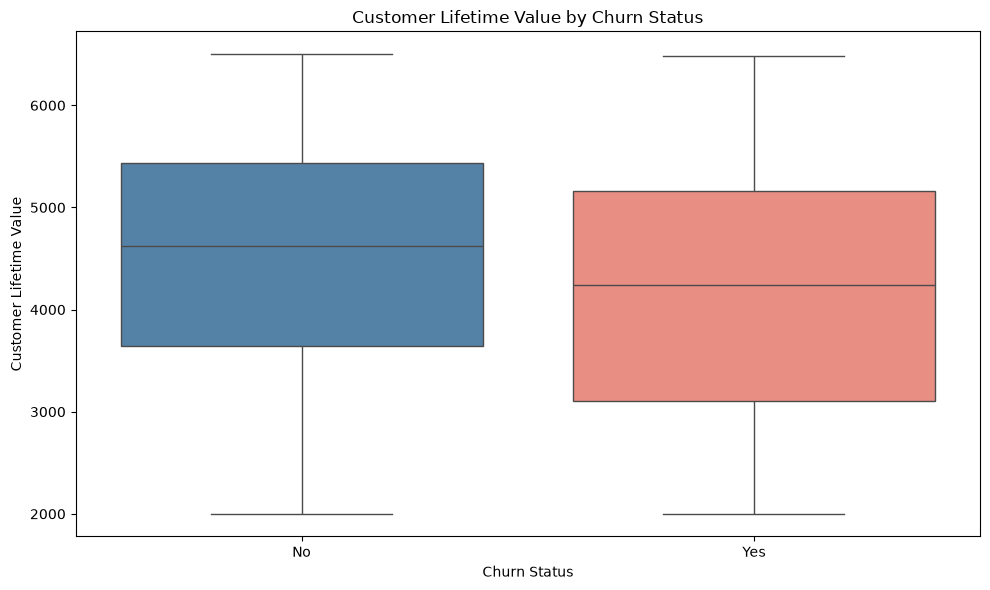

In [48]:
# Customer lifetime value vs churn

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Churn Label",
    y="CLTV",
    order=["No", "Yes"],
    hue="Churn Label",
    palette={"No": "steelblue", "Yes": "salmon"},
    legend=False
)

plt.title("Customer Lifetime Value by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Customer Lifetime Value")
plt.tight_layout()
plt.show()


# **Geographic Churn Analysis**

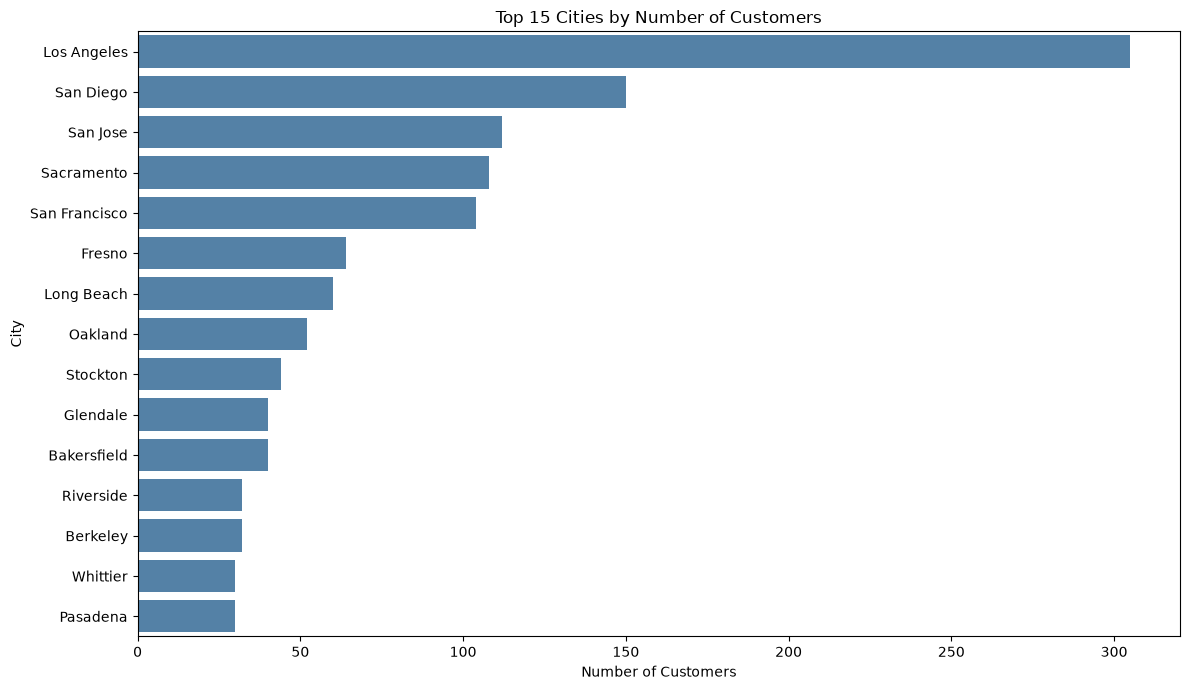

In [49]:
# Top 15 cities by customer count

top_cities = df["City"].value_counts().head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_cities.values,
    y=top_cities.index,
    color="steelblue"
)

plt.title("Top 15 Cities by Number of Customers")
plt.xlabel("Number of Customers")
plt.ylabel("City")
plt.tight_layout()
plt.show()

,Customer_Count,Churned_Customers,Churn_Rate
City,,,
San Diego,150,50,33.33
Glendale,40,13,32.50
Pasadena,30,9,30.00
San Francisco,104,31,29.81
Los Angeles,305,90,29.51
Berkeley,32,9,28.12
Stockton,44,12,27.27
San Jose,112,29,25.89
Oakland,52,13,25.00


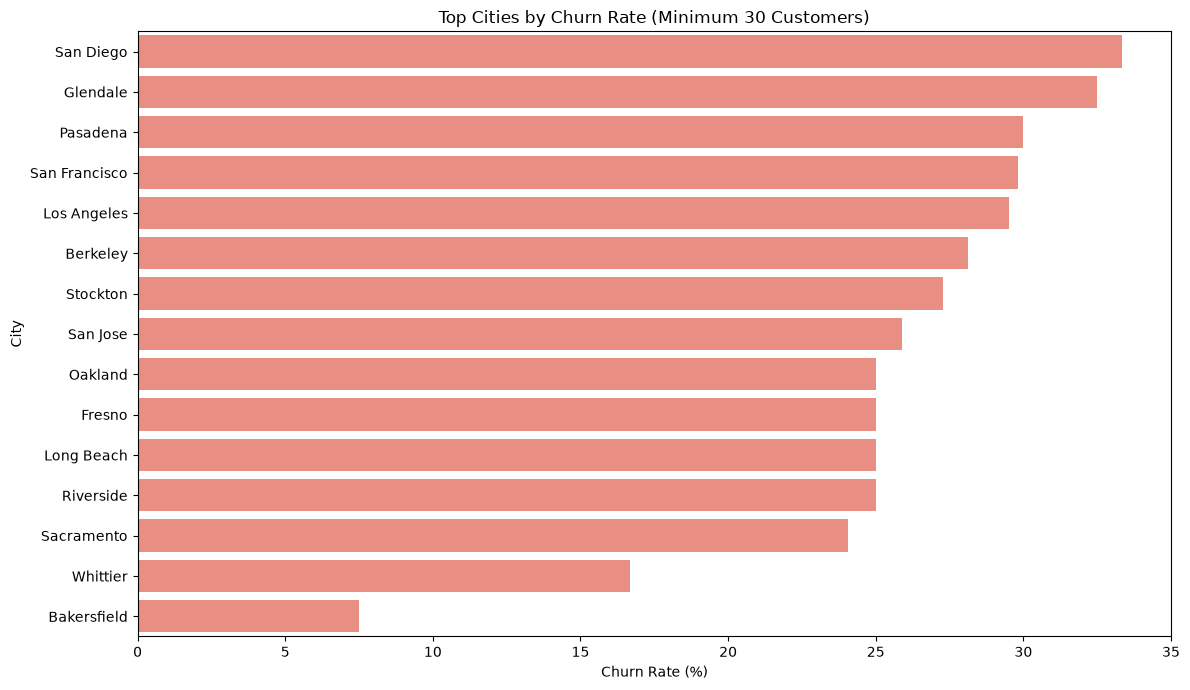

In [50]:
# City-wise churn rate

city_churn = (
    df.groupby("City")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Churned_Customers=("Churn Value", "sum"),
        Churn_Rate=("Churn Value", "mean")
    )
)

city_churn["Churn_Rate"] *= 100

city_churn_filtered = city_churn[
    city_churn["Customer_Count"] >= 30
]

top_churn_cities = (
    city_churn_filtered
    .sort_values("Churn_Rate", ascending=False)
    .head(15)
)

display(top_churn_cities.round(2))

if not top_churn_cities.empty:

    plt.figure(figsize=(12, 7))

    sns.barplot(
        x=top_churn_cities["Churn_Rate"],
        y=top_churn_cities.index,
        color="salmon"
    )

    plt.title("Top Cities by Churn Rate (Minimum 30 Customers)")
    plt.xlabel("Churn Rate (%)")
    plt.ylabel("City")
    plt.tight_layout()
    plt.show()

else:
    print("No cities meet the minimum customer threshold.")

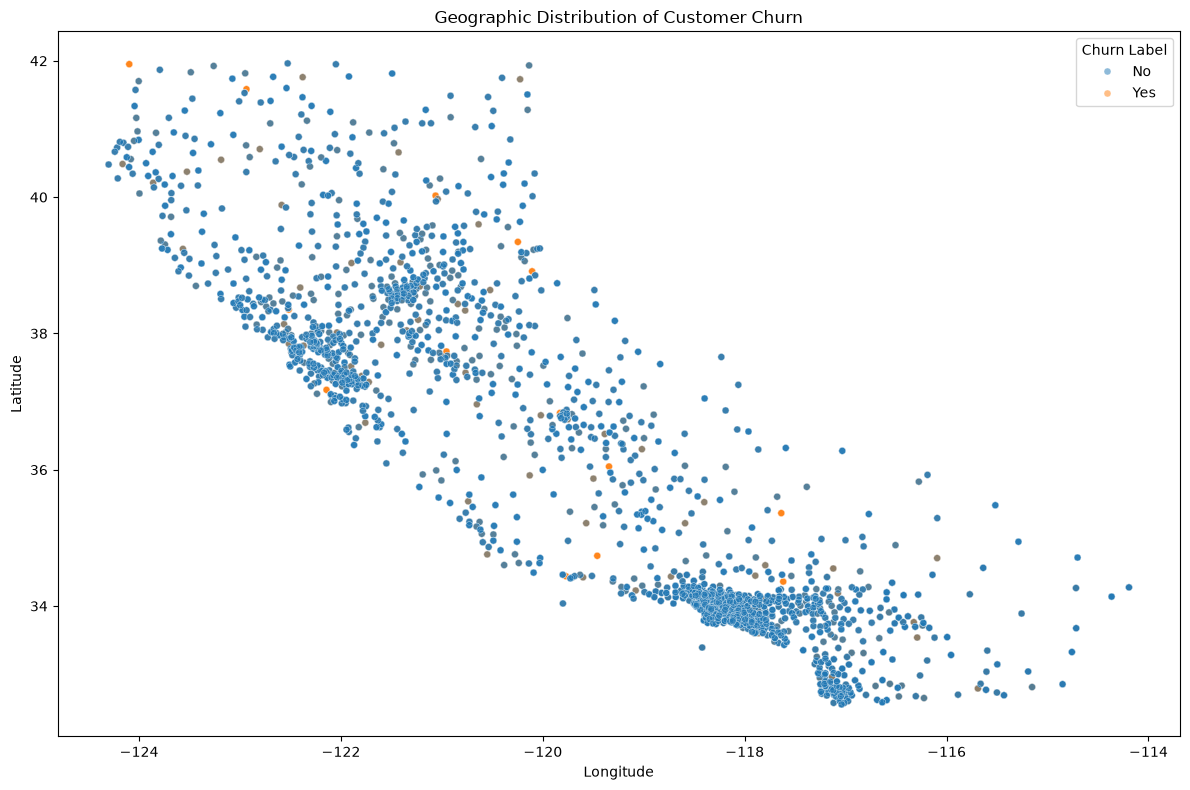

In [51]:
# Geographic scatter plot

plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=df,
    x="Longitude",
    y="Latitude",
    hue="Churn Label",
    hue_order=["No", "Yes"],
    alpha=0.5,
    s=25
)

plt.title("Geographic Distribution of Customer Churn")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.tight_layout()
plt.show()

# **Churn Reason Analysis**

Churn Reason
Attitude of support person                   192
Competitor offered higher download speeds    189
Competitor offered more data                 162
Don't know                                   154
Competitor made better offer                 140
Attitude of service provider                 135
Competitor had better devices                130
Network reliability                          103
Product dissatisfaction                      102
Price too high                                98
Service dissatisfaction                       89
Lack of self-service on Website               88
Extra data charges                            57
Moved                                         53
Limited range of services                     44
Lack of affordable download/upload speed      44
Long distance charges                         44
Poor expertise of phone support               20
Poor expertise of online support              19
Deceased                                       6
Name: c

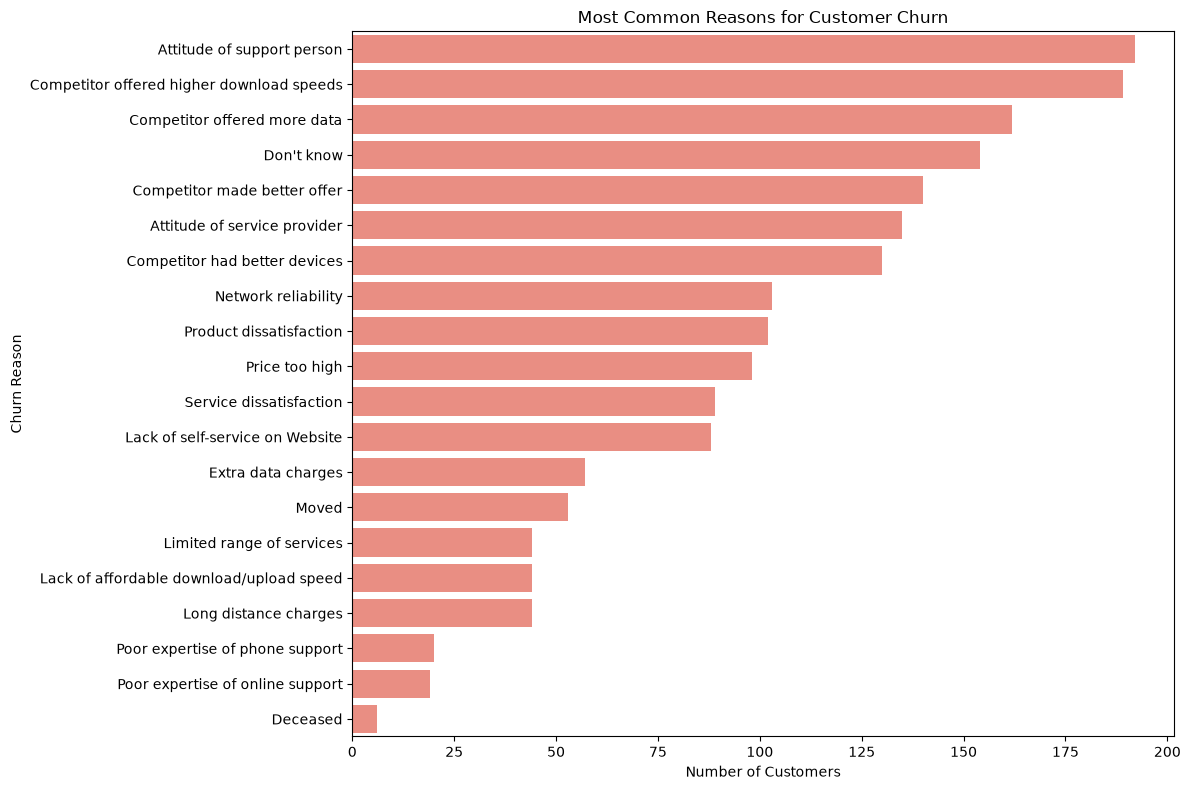

In [53]:
# Most common churn reasons

churned_customers = df[
    df["Churn Value"] == 1
].copy()

churn_reasons = (
    churned_customers["Churn Reason"]
    .value_counts()
)

display(churn_reasons)

plt.figure(figsize=(12, 8))

sns.barplot(
    x=churn_reasons.values,
    y=churn_reasons.index,
    color="salmon"
)

plt.title("Most Common Reasons for Customer Churn")
plt.xlabel("Number of Customers")
plt.ylabel("Churn Reason")
plt.tight_layout()
plt.show()

In [54]:
# Churn reason percentages

reason_percentages = (
    churned_customers["Churn Reason"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

display(
    reason_percentages.to_frame(
        name="Percentage of Recorded Reasons"
    )
)

,Percentage of Recorded Reasons
Churn Reason,
Attitude of support person,10.27
Competitor offered higher download speeds,10.11
Competitor offered more data,8.67
Don't know,8.24
Competitor made better offer,7.49
Attitude of service provider,7.22
Competitor had better devices,6.96
Network reliability,5.51
Product dissatisfaction,5.46


Contract,Month-to-month,One year,Two year
Churn Reason,,,
Attitude of service provider,115,17,3
Attitude of support person,174,16,2
Competitor had better devices,116,10,4
Competitor made better offer,126,10,4
Competitor offered higher download speeds,161,23,5
Competitor offered more data,140,16,6
Deceased,6,0,0
Don't know,141,12,1
Extra data charges,53,1,3


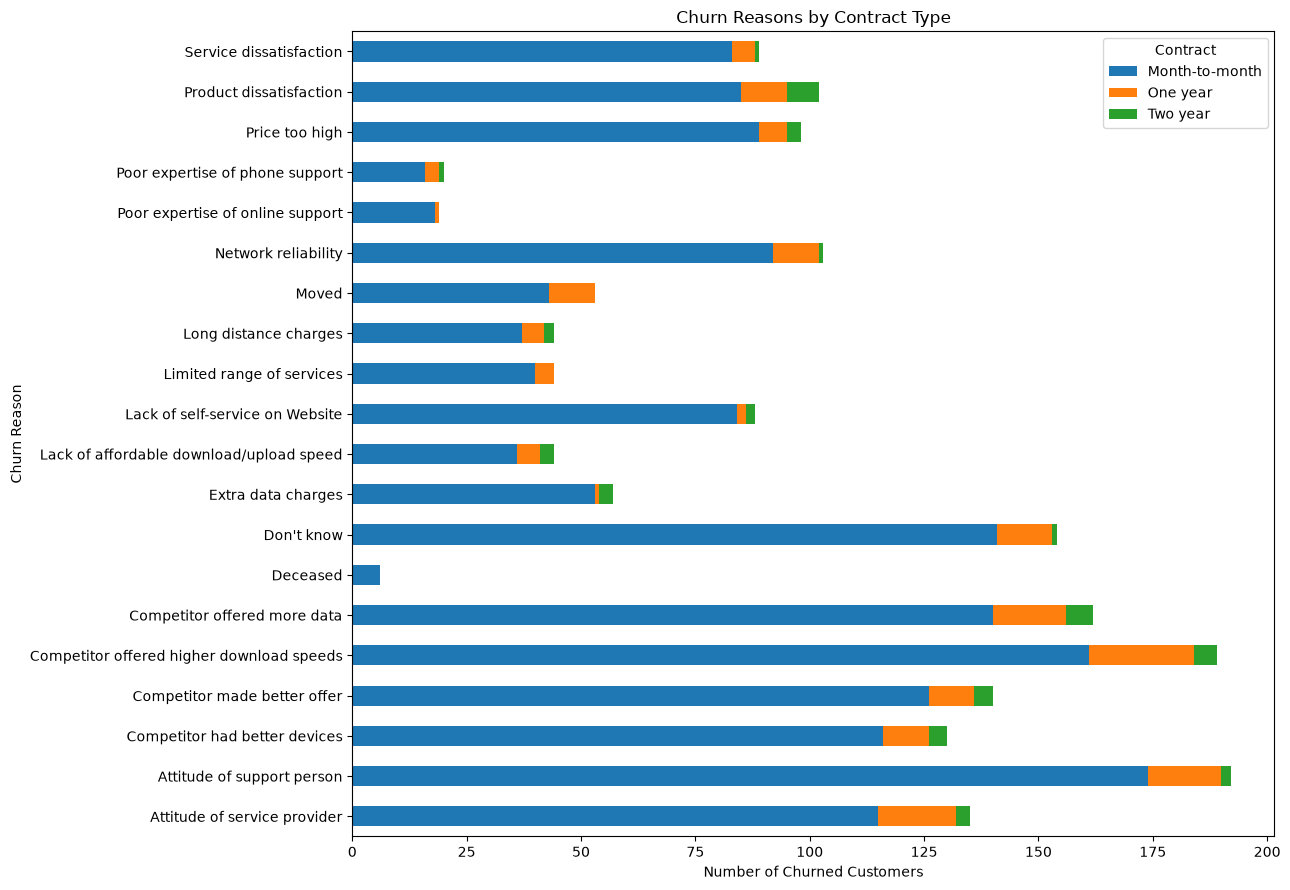

In [55]:
# Churn reasons by contract type

reason_contract = pd.crosstab(
    churned_customers["Churn Reason"],
    churned_customers["Contract"]
)

display(reason_contract)

reason_contract.plot(
    kind="barh",
    stacked=True,
    figsize=(13, 9)
)

plt.title("Churn Reasons by Contract Type")
plt.xlabel("Number of Churned Customers")
plt.ylabel("Churn Reason")
plt.legend(title="Contract")
plt.tight_layout()
plt.show()

# **Statistical Analysis**

In [56]:
from scipy.stats import chi2_contingency, mannwhitneyu

In [57]:
# Chi-square tests for categorical features

chi_square_results = []

all_categorical_features = (
    categorical_features + service_features
)

for col in all_categorical_features:

    contingency_table = pd.crosstab(
        df[col],
        df["Churn Value"]
    )

    if contingency_table.shape[0] < 2:
        continue

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    chi_square_results.append({
        "Feature": col,
        "Chi-Square": chi2,
        "P-Value": p_value,
        "Significant (p < 0.05)": p_value < 0.05
    })

chi_square_df = pd.DataFrame(
    chi_square_results
).sort_values("P-Value")

display(chi_square_df)

,Feature,Chi-Square,P-Value,Significant (p < 0.05)
6,Contract,1184.596572,5.863038e-258,True
10,Online Security,849.998968,2.661150e-185,True
13,Tech Support,828.197068,1.443084e-180,True
5,Internet Service,732.309590,9.571788e-160,True
8,Payment Method,648.142327,3.682355e-140,True
11,Online Backup,601.812790,2.079759e-131,True
12,Device Protection,558.419369,5.505219e-122,True
3,Dependents,433.734379,2.500972e-96,True
15,Streaming Movies,375.661479,2.667757e-82,True
14,Streaming TV,374.203943,5.528994e-82,True


In [58]:
# Mann-Whitney U tests for numerical features

mann_whitney_results = []

for col in eda_numeric_cols:

    churned = df.loc[
        df["Churn Value"] == 1, col
    ].dropna()

    retained = df.loc[
        df["Churn Value"] == 0, col
    ].dropna()

    statistic, p_value = mannwhitneyu(
        churned,
        retained,
        alternative="two-sided"
    )

    mann_whitney_results.append({
        "Feature": col,
        "U Statistic": statistic,
        "P-Value": p_value,
        "Significant (p < 0.05)": p_value < 0.05
    })

mann_whitney_df = pd.DataFrame(
    mann_whitney_results
).sort_values("P-Value")

display(mann_whitney_df)

,Feature,U Statistic,P-Value,Significant (p < 0.05)
0,Tenure Months,2515538.0,2.419636e-208,True
2,Total Charges,3360665.0,1.995985e-84,True
1,Monthly Charges,6003125.5,3.311628e-54,True
3,CLTV,4053479.5,3.244484e-25,True


# **EDA Summary and Modelling Recommendations**

In [59]:
# Overall churn statistics

total_customers = len(df)

churned_count = int(df["Churn Value"].sum())

retained_count = total_customers - churned_count

overall_churn_rate = (
    churned_count / total_customers
) * 100

print("=" * 60)
print("CUSTOMER CHURN EDA SUMMARY")
print("=" * 60)

print(f"Total Customers: {total_customers}")
print(f"Churned Customers: {churned_count}")
print(f"Retained Customers: {retained_count}")
print(f"Overall Churn Rate: {overall_churn_rate:.2f}%")

print("\nAverage Tenure by Churn Status:")
display(
    df.groupby("Churn Label")["Tenure Months"]
    .mean()
    .round(2)
)

print("\nAverage Monthly Charges by Churn Status:")
display(
    df.groupby("Churn Label")["Monthly Charges"]
    .mean()
    .round(2)
)

CUSTOMER CHURN EDA SUMMARY
Total Customers: 7043
Churned Customers: 1869
Retained Customers: 5174
Overall Churn Rate: 26.54%

Average Tenure by Churn Status:


Churn Label
No     37.57
Yes    17.98
Name: Tenure Months, dtype: float64


Average Monthly Charges by Churn Status:


Churn Label
No     61.27
Yes    74.44
Name: Monthly Charges, dtype: float64

In [60]:
# Identify categorical groups with high churn rates

high_churn_groups = []

for col in all_categorical_features:

    summary = (
        df.groupby(col, dropna=False)["Churn Value"]
        .agg(["count", "mean"])
        .reset_index()
    )

    summary = summary[
        summary["count"] >= 30
    ].copy()

    for _, row in summary.iterrows():

        high_churn_groups.append({
            "Feature": col,
            "Category": row[col],
            "Customer Count": int(row["count"]),
            "Churn Rate (%)": row["mean"] * 100
        })

high_churn_df = pd.DataFrame(
    high_churn_groups
).sort_values(
    "Churn Rate (%)",
    ascending=False
)

display(high_churn_df.head(20).round(2))

,Feature,Category,Customer Count,Churn Rate (%)
20,Payment Method,Electronic check,2365,45.29
13,Contract,Month-to-month,3875,42.71
11,Internet Service,Fiber optic,3096,41.89
25,Online Security,No,3498,41.77
3,Senior Citizen,Yes,1142,41.68
34,Tech Support,No,3473,41.64
28,Online Backup,No,3088,39.93
31,Device Protection,No,3095,39.13
40,Streaming Movies,No,2785,33.68
17,Paperless Billing,Yes,4171,33.57


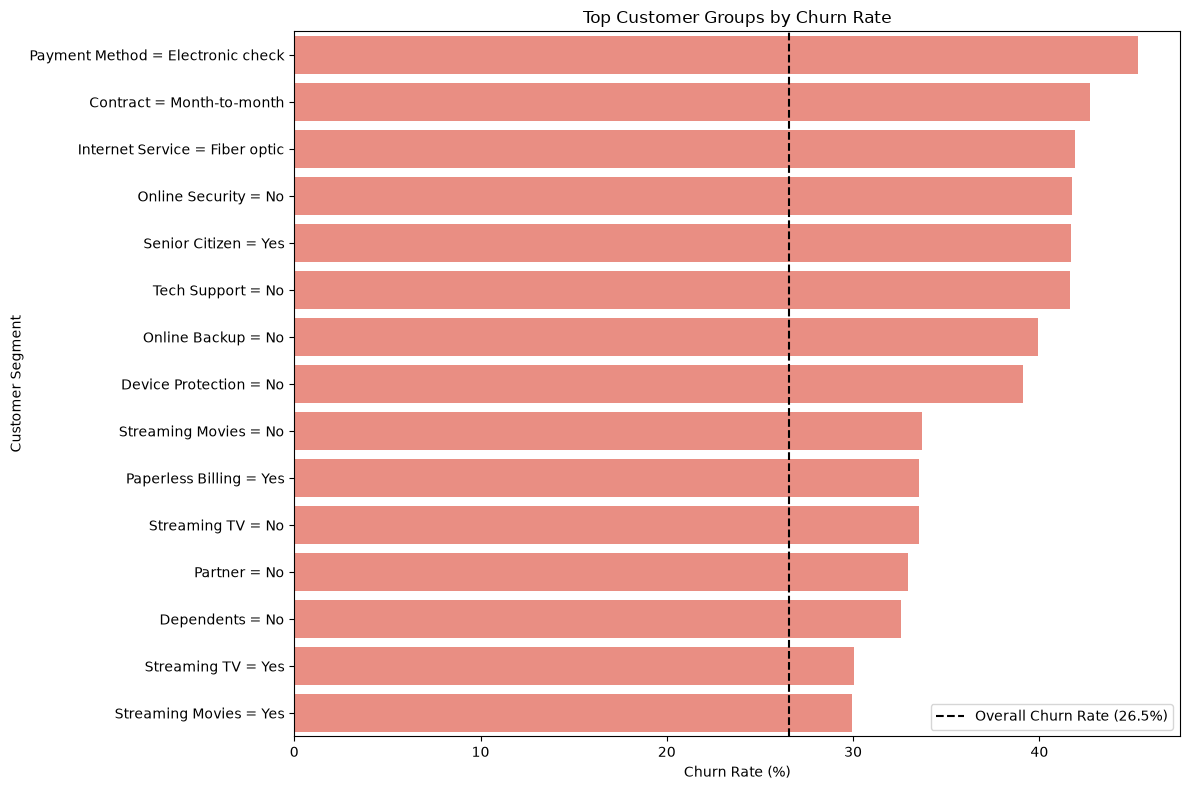

In [61]:
# Visualize top high-churn customer groups

top_groups = high_churn_df.head(15).copy()

top_groups["Segment"] = (
    top_groups["Feature"].astype(str)
    + " = "
    + top_groups["Category"].astype(str)
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_groups,
    x="Churn Rate (%)",
    y="Segment",
    color="salmon"
)

plt.axvline(
    overall_churn_rate,
    color="black",
    linestyle="--",
    label=f"Overall Churn Rate ({overall_churn_rate:.1f}%)"
)

plt.title("Top Customer Groups by Churn Rate")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Customer Segment")
plt.legend()
plt.tight_layout()
plt.show()

In [62]:
# Identify columns that should be excluded from ML input

exclude_columns = [
    "CustomerID",
    "Count",
    "Country",
    "State",
    "Lat Long",
    "Churn Label",
    "Churn Value",
    "Churn Score",
    "Churn Reason",
    "Tenure Group",
    "Monthly Charge Group"
]

# These columns can also be excluded in the initial
# baseline model to reduce high-cardinality and
# potentially redundant geographic information.

baseline_geo_exclusions = [
    "City",
    "Zip Code",
    "Latitude",
    "Longitude"
]

feature_columns = [
    col for col in df.columns
    if col not in exclude_columns + baseline_geo_exclusions
]

print("Number of baseline input features:", len(feature_columns))

print("\nBaseline ML Input Features:")

for col in feature_columns:
    print("-", col)

print("\nTarget Variable: Churn Value")

Number of baseline input features: 20

Baseline ML Input Features:
- Gender
- Senior Citizen
- Partner
- Dependents
- Tenure Months
- Phone Service
- Multiple Lines
- Internet Service
- Online Security
- Online Backup
- Device Protection
- Tech Support
- Streaming TV
- Streaming Movies
- Contract
- Paperless Billing
- Payment Method
- Monthly Charges
- Total Charges
- CLTV

Target Variable: Churn Value


In [63]:
# Final EDA data quality report

eda_quality_report = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isna().sum().values,
    "Missing Percentage": (
        df.isna().mean().values * 100
    ),
    "Unique Values": df.nunique(dropna=True).values
})

display(
    eda_quality_report.round(2)
)

,Column,Data Type,Missing Values,Missing Percentage,Unique Values
0,CustomerID,str,0,0.00,7043
1,Count,int64,0,0.00,1
2,Country,str,0,0.00,1
3,State,str,0,0.00,1
4,City,str,0,0.00,1129
5,Zip Code,int64,0,0.00,1652
6,Lat Long,str,0,0.00,1652
7,Latitude,float64,0,0.00,1652
8,Longitude,float64,0,0.00,1651
9,Gender,str,0,0.00,2


In [65]:
# Final EDA summary

print("=" * 65)
print("FINAL EDA REPORT")
print("=" * 65)

print(f"\nDataset Shape: {df.shape}")
print(f"Overall Churn Rate: {overall_churn_rate:.2f}%")

print("\nTotal Missing Values:")
print(df.isna().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nTop 5 High-Churn Customer Groups:")
display(high_churn_df.head(5).round(2))

print("\nNumerical Feature Correlations with Churn:")
display(target_correlation.round(3))

print("\nEDA Completed Successfully!")

FINAL EDA REPORT

Dataset Shape: (7043, 35)
Overall Churn Rate: 26.54%

Total Missing Values:
5185

Duplicate Rows:
0

Top 5 High-Churn Customer Groups:


,Feature,Category,Customer Count,Churn Rate (%)
20,Payment Method,Electronic check,2365,45.29
13,Contract,Month-to-month,3875,42.71
11,Internet Service,Fiber optic,3096,41.89
25,Online Security,No,3498,41.77
3,Senior Citizen,Yes,1142,41.68



Numerical Feature Correlations with Churn:


Tenure Months     -0.352
Total Charges     -0.199
CLTV              -0.127
Monthly Charges    0.193
Name: Churn Value, dtype: float64


EDA Completed Successfully!
